# README
- **Author**: 詹明翰、謝子詮、曾翊涵（沿用已確認共同作者，不推定個別分工）
- **Created At**: 2026-11-26
- **Last Modified At**: 2026-11-26

## What does this file do?
Unit 1.2 行政里界正式品質驗證：來源與歷史適用、CRS／屬性、個體幾何、拓樸／孔洞、
面積診斷及合成資料歸里規則。保留教師 data/code 範本的README欄位順序；
依本單元授權將正式處理／寫檔區改為唯讀GIS診斷，不建立修復後資料。
所有union、intersection、dissolve及面積只在記憶體供驗證，不變更原始geometry。

## What does this file take?
五個原始配套hash須符合Unit 0.5；另讀兩份已存在Notebook作版本／限制銜接，不重新執行。
- `data/raw/G97_A_CAVLGE_P.shp`；SHA-256：`f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc`
- `data/raw/G97_A_CAVLGE_P.shx`；SHA-256：`ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e`
- `data/raw/G97_A_CAVLGE_P.dbf`；SHA-256：`2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577`
- `data/raw/G97_A_CAVLGE_P.prj`；SHA-256：`8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5`
- `data/raw/G97_A_CAVLGE_P.cpg`；SHA-256：`3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824`
- `data/raw/taipei_village_boundaries_raw_documentation.ipynb`；SHA-256：`74c1c7e8fca3f5c5a82a94282f25dd42b6c2ba91e952e6408c3bd307fb269fcf`
- `data/code/taipei_2024_2025_crash_validation.ipynb`；SHA-256：`3674d0043289f75079b46b90076795967563d721a91e303a568ecf85a25c0c6d`
專案脈絡見[PROJECT.md](../../PROJECT.md)。本Notebook不讀取實際事故CSV、人口或都市計畫圖資。

## What does this file output?
- 本Notebook保存實際診斷表、候選原則與七類必要圖表，均標示「資料品質診斷」。
- Output key: `boundary_validation_documentation`；Role: 驗證文件，不是analysis／train／test資料。
- Expected schema and row-count rules: 456個原始面單元；各表明列實際樣本與單位，不以斷言強迫幾何沒有問題。
- Verification status / SHA-256: 保存執行輸出及末尾逐檔保護檢查；未產生processed檔，故無cleaned-data hash。
- Downstream finding input: not applicable；未建立修復後Shapefile、正式里面積表或事故歸里結果。
- 圖片另寫Git忽略的`data/temp/unit12_validation/`供目視核對；正式Notebook內嵌相同圖片，不依賴暫存圖片才能閱讀。

使用`.venv/Scripts/python.exe`與DSSI Urban Crash乾淨kernel，根目錄採AGENTS.md＋templates/可攜定位。
尚未確認的歷史邊界、AREA單位、外部覆蓋及事故datum保持未知，不下載額外參考圖資。


In [1]:
from pathlib import Path
import ast, hashlib, json, math, os, platform, struct, sys, importlib.metadata as metadata
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Point, Polygon, box
import nbformat
from IPython.display import display, Markdown

def root_from(start=None):
    start=Path.cwd() if start is None else Path(start)
    for p in (start.resolve(),*start.resolve().parents):
        if (p/'AGENTS.md').is_file() and (p/'templates').is_dir():return p
    raise FileNotFoundError('Open in the project containing AGENTS.md and templates/.')
ROOT=root_from();TEMP=ROOT/'data/temp/unit12_validation';TEMP.mkdir(parents=True,exist_ok=True)
assert Path(sys.executable).resolve()==(ROOT/'.venv/Scripts/python.exe').resolve()
assert sys.prefix!=sys.base_prefix
os.environ['MPLCONFIGDIR']=str(TEMP/'matplotlib');os.environ['PROJ_NETWORK']='OFF'
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
from matplotlib import font_manager
from matplotlib.ft2font import FT2Font
font=Path(os.environ['WINDIR'])/'Fonts/msjh.ttc'
font_manager.fontManager.addfont(str(font));family=font_manager.FontProperties(fname=str(font)).get_name()
assert all(FT2Font(str(font)).get_char_index(ord(c)) for c in '資料品質診斷行政里界面積重疊孔洞')
plt.rcParams.update({'font.family':[family,'DejaVu Sans'],'axes.unicode_minus':False,'mathtext.fontset':'dejavusans','figure.dpi':110})
pd.set_option('display.max_colwidth',110)

def source_file(relative):
    rel=Path(relative)
    if rel.is_absolute() or '..' in rel.parts:raise ValueError('Exact project-relative input required')
    p=(ROOT/rel).resolve()
    if not p.is_relative_to(ROOT/'data') or not p.is_file():raise FileNotFoundError(relative)
    return p
def sha(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def show(title,frame,block=25):
    display(Markdown('**'+title+'**'))
    if not len(frame):display(Markdown('無符合紀錄。'))
    for start in range(0,len(frame),block):display(frame.iloc[start:start+block])
FIGURES=[]
def finish_figure(fig,name):
    fig.savefig(TEMP/name,dpi=140,bbox_inches='tight')
    FIGURES.append('data/temp/unit12_validation/'+name)
    plt.show();plt.close(fig)
print({'python':platform.python_version(),'interpreter_matches_project_venv':True,
       'packages':{k:metadata.version(k) for k in ['geopandas','shapely','pyproj','pyogrio','pandas','numpy','matplotlib','nbclient']},
       'GEOS':shapely.geos_version_string,'network_in_notebook':'none','Chinese_font':family})


{'python': '3.12.2', 'interpreter_matches_project_venv': True, 'packages': {'geopandas': '1.2.0', 'shapely': '2.2.0', 'pyproj': '3.8.0', 'pyogrio': '0.13.0', 'pandas': '3.1.1', 'numpy': '2.5.5', 'matplotlib': '3.11.2', 'nbclient': '0.11.0'}, 'GEOS': '3.14.1', 'network_in_notebook': 'none', 'Chinese_font': 'Microsoft JhengHei'}


In [2]:
EXPECTED_SHA256 = {'data/raw/G97_A_CAVLGE_P.shp': 'f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc', 'data/raw/G97_A_CAVLGE_P.shx': 'ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e', 'data/raw/G97_A_CAVLGE_P.dbf': '2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577', 'data/raw/G97_A_CAVLGE_P.prj': '8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5', 'data/raw/G97_A_CAVLGE_P.cpg': '3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824', 'data/raw/taipei_village_boundaries_raw_documentation.ipynb': '74c1c7e8fca3f5c5a82a94282f25dd42b6c2ba91e952e6408c3bd307fb269fcf', 'data/code/taipei_2024_2025_crash_validation.ipynb': '3674d0043289f75079b46b90076795967563d721a91e303a568ecf85a25c0c6d'}
OUTPUTS={}
manifest=[]
for relative,digest in EXPECTED_SHA256.items():
    p=source_file(relative);actual=sha(p)
    if actual!=digest:raise ValueError(f'Input version changed: {relative}')
    manifest.append({'input':relative,'bytes':p.stat().st_size,'SHA-256':actual})
show('表1：原始配套與銜接文件逐檔hash',pd.DataFrame(manifest),block=7)
raw_document=nbformat.read(source_file('data/raw/taipei_village_boundaries_raw_documentation.ipynb'),as_version=4)
unit05=ast.literal_eval(ast.parse(next(c.source for c in raw_document.cells if c.cell_type=='code' and c.source.startswith('EXPECTED_SHA256 ='))).body[0].value)
assert all(EXPECTED_SHA256[p]==digest for p,digest in unit05.items())
boundary=gpd.read_file(source_file('data/raw/G97_A_CAVLGE_P.shp'),engine='pyogrio',encoding='utf-8')
original_wkb=boundary.geometry.to_wkb().copy()
print({'raw_shape':boundary.shape,'source_hash_matches_Unit_0_5':True,'existing_notebooks_executed':False})


**表1：原始配套與銜接文件逐檔hash**

,input,bytes,SHA-256
0,data/raw/G97_A_CAVLGE_P.shp,765784,f7fb4813a2283198ca564f5686823c454c5fd832d2f6981a2ee88a94719be3cc
1,data/raw/G97_A_CAVLGE_P.shx,3748,ab7bc5e63229f676d3580b68e98db59b91a2d327c74ca23b0000ca1c568d414e
2,data/raw/G97_A_CAVLGE_P.dbf,272706,2f43f92e84279a45b2512cf453e9b72f706d1ad1402665c946b1a354f75d8577
3,data/raw/G97_A_CAVLGE_P.prj,399,8dac7d82ea889063f9eaa7df408fcaeb7307d32831ea973b6534d0139a4523c5
4,data/raw/G97_A_CAVLGE_P.cpg,5,3ad3031f5503a4404af825262ee8232cc04d4ea6683d42c5dd0a2f2a27ac9824
5,data/raw/taipei_village_boundaries_raw_documentation.ipynb,106813,74c1c7e8fca3f5c5a82a94282f25dd42b6c2ba91e952e6408c3bd307fb269fcf
6,data/code/taipei_2024_2025_crash_validation.ipynb,1195733,3674d0043289f75079b46b90076795967563d721a91e303a568ecf85a25c0c6d


{'raw_shape': (456, 29), 'source_hash_matches_Unit_0_5': True, 'existing_notebooks_executed': False}


## 1. Source and Historical Validity
已查閱官方里界資料頁、歷史調整與研究年末統計，並搜尋113／114年里界、里行政區域調整及歷史版本。
本次未取得可計算比較的2024／2025兩份歷史向量，也未取得涵蓋所有增減、合併、更名、微調的逐項異動清冊。
找到的歷史界說與一般行政調整程序不能用來斷言研究期間「沒有調整」。
2024／2025年底里數一致、名稱／代碼一致與實際幾何一致分為三個不同證據層次。
本單元沒有下載或替換圖資，也不把網頁、檔案時間或G97檔名當作邊界生效年代。


In [3]:
EVIDENCE = [{'ID': 'H1', '來源': '民政局／臺北市里界圖', 'URL': 'https://data.taipei/dataset/detail?id=6b17b31d-4e16-495e-95b1-9fd1f47c80d8', '查閱日': '2026-11-26', '查得內容': '供公務GIS參考、456里、TWD97；收錄2010-08-17至2025-06-17；資源更新2026-09-21 14:26:43', '證據限度': '不是本機生效版本或2024／2025逐年幾何；僅列AREA欄名，未定義單位／算法'}, {'ID': 'H2', '來源': '市統計年報表267 各區里鄰戶數及自治人員數', 'URL': 'https://www-ws.gov.taipei/001/Upload/367/relfile/48245/8011552/77090739-2147-45bc-9e12-03b5c5b7f6e8.pdf', '查閱日': '2026-11-26', '查得內容': 'p.1列2024年底及2025年底各456里，並列各區里數', '證據限度': '確認年末數量，不能排除年內等數量調整、更名或邊界微調，也未提供逐里幾何'}, {'ID': 'H3', '來源': '民政局 第6期里調整新聞稿', 'URL': 'https://ca.gov.taipei/News_Content.aspx?n=080D7D061A30C74B&s=7CF16104FF3B7488&sms=72544237BBE4C5F6', '查閱日': '2026-11-26', '查得內容': '2010-09-01新增7里，由449增為456', '證據限度': '歷史制度背景；不是2024–2025無調整證明'}, {'ID': 'H4', '來源': '政府網站2010臺北市區里界說（士林）歷史參考', 'URL': 'https://www-ws.gov.taipei/001/Upload/public/Attachment/462020283951.pdf', '查閱日': '2026-11-26', '查得內容': '2010期區里界說之編纂及歷史文字圖說可作參考', '證據限度': '不是2024／2025可比GIS歷史向量；不能因近期上架就認定邊界近期生效'}, {'ID': 'H5', '來源': '113年交通統計年報 表44人口概況', 'URL': 'https://www-ws.gov.taipei/Download.ashx?icon=.pdf&n=MjAyNCBTVEFUSVNUSUNBTCBZRUFSQk9PSyBPRiBUUkFOU1BPUlRBVElPTixUQUlQRUkgQ0lUWS5wZGY%3D&u=LzAwMS9VcGxvYWQvMzkxL3JlbGZpbGUvMTk3OTAvODIxMDA2Ny9kNDNiYTI2ZC0zNGE2LTQ1Y2MtODY3MS05MGIxYWEwMjU4MjYucGRm', '查閱日': '2026-11-26', '查得內容': '2024年底全市統計土地面積271.7997km²、456里', '證據限度': '只作統計量旁證，不是版本相容的獨立市界幾何；面積差不能直接當外部漏覆蓋量'}]
show('表2：來源、歷史適用性與AREA證據',pd.DataFrame(EVIDENCE),block=5)
dbf=source_file('data/raw/G97_A_CAVLGE_P.dbf').read_bytes()
dbf_date=f'{1900+dbf[1]:04d}-{dbf[2]:02d}-{dbf[3]:02d}'
print({'DBF_header_last_update_date':dbf_date,'DBF_record_count':int.from_bytes(dbf[4:8],'little'),
       'interpretation':'DBF header records a write date, not download date or geometry effective date',
       'local_geometry_effective_vintage':'unconfirmed','2024_2025_geometry_equality':'not established'})
show('表3：研究期間適用性分層判斷',pd.DataFrame([
 {'層次':'里數','結果':'官方兩年年底均456；本機456','仍不能推論':'年內未曾變動或幾何相同'},
 {'層次':'里名／代碼','結果':'本機CPTVID／名稱唯一；Unit0.5曾記人口代碼集合一致，本次不重跑人口','仍不能推論':'完整官方年度碼表與每里更名史皆已認證'},
 {'層次':'實際地理邊界','結果':'沒有2024／2025可比向量，未建立幾何版本相等證據','仍不能推論':'現有快照就是兩年原生行政界'},
 {'層次':'固定研究地理單位','結果':'可提案兩年共用同一hash快照，須學生審查','仍不能推論':'等同歷史里界；人口若按歷史邊界統計仍可能錯配'}]))


**表2：來源、歷史適用性與AREA證據**

,ID,來源,URL,查閱日,查得內容,證據限度
0,H1,民政局／臺北市里界圖,https://data.taipei/dataset/detail?id=6b17b31d-4e16-495e-95b1-9fd1f47c80d8,2026-11-26,供公務GIS參考、456里、TWD97；收錄2010-08-17至2025-06-17；資源更新2026-09-21 14:26:43,不是本機生效版本或2024／2025逐年幾何；僅列AREA欄名，未定義單位／算法
1,H2,市統計年報表267 各區里鄰戶數及自治人員數,https://www-ws.gov.taipei/001/Upload/367/relfile/48245/8011552/77090739-2147-45bc-9e12-03b5c5b7f6e8.pdf,2026-11-26,p.1列2024年底及2025年底各456里，並列各區里數,確認年末數量，不能排除年內等數量調整、更名或邊界微調，也未提供逐里幾何
2,H3,民政局 第6期里調整新聞稿,https://ca.gov.taipei/News_Content.aspx?n=080D7D061A30C74B&s=7CF16104FF3B7488&sms=72544237BBE4C5F6,2026-11-26,2010-09-01新增7里，由449增為456,歷史制度背景；不是2024–2025無調整證明
3,H4,政府網站2010臺北市區里界說（士林）歷史參考,https://www-ws.gov.taipei/001/Upload/public/Attachment/462020283951.pdf,2026-11-26,2010期區里界說之編纂及歷史文字圖說可作參考,不是2024／2025可比GIS歷史向量；不能因近期上架就認定邊界近期生效
4,H5,113年交通統計年報 表44人口概況,https://www-ws.gov.taipei/Download.ashx?icon=.pdf&n=MjAyNCBTVEFUSVNUSUNBTCBZRUFSQk9PSyBPRiBUUkFOU1BPUlRBVE...,2026-11-26,2024年底全市統計土地面積271.7997km²、456里,只作統計量旁證，不是版本相容的獨立市界幾何；面積差不能直接當外部漏覆蓋量


{'DBF_header_last_update_date': '2026-09-16', 'DBF_record_count': 456, 'interpretation': 'DBF header records a write date, not download date or geometry effective date', 'local_geometry_effective_vintage': 'unconfirmed', '2024_2025_geometry_equality': 'not established'}


**表3：研究期間適用性分層判斷**

,層次,結果,仍不能推論
0,里數,官方兩年年底均456；本機456,年內未曾變動或幾何相同
1,里名／代碼,本機CPTVID／名稱唯一；Unit0.5曾記人口代碼集合一致，本次不重跑人口,完整官方年度碼表與每里更名史皆已認證
2,實際地理邊界,沒有2024／2025可比向量，未建立幾何版本相等證據,現有快照就是兩年原生行政界
3,固定研究地理單位,可提案兩年共用同一hash快照，須學生審查,等同歷史里界；人口若按歷史邊界統計仍可能錯配


## 2. CRS and Attribute Validation
只讀PRJ與CPG並核對實際reader結果。CPTVID保留字串，不轉成任何人口或其他行政碼。
DBF必要欄位的型態、缺失及區里唯一性逐一檢查；未取得的官方縮寫定義不在本單元補造。


In [4]:
assert boundary.crs.to_epsg()==3826
assert all(isinstance(v,str) for v in boundary['CPTVID'].dropna())
crs=boundary.crs
print({'PRJ':source_file('data/raw/G97_A_CAVLGE_P.prj').read_text(encoding='ascii'),
       'CPG':source_file('data/raw/G97_A_CAVLGE_P.cpg').read_text(encoding='ascii'),
       'EPSG':crs.to_epsg(),'datum':crs.datum.name,'projection':crs.coordinate_operation.method_name,
       'axes':[{'name':a.name,'direction':a.direction,'unit':a.unit_name} for a in crs.axis_info]})
attributes=pd.DataFrame([{'欄位':c,'讀入型態':str(boundary[c].dtype),'缺失':int(boundary[c].isna().sum()),
                         '非缺失相異數':int(boundary[c].nunique())} for c in boundary])
show('表4：全部屬性型態與缺失（geometry非DBF屬性）',attributes,block=15)
district_counts=boundary['TNAME'].value_counts().rename('本機里數').to_frame()
official_counts={'松山區':33,'信義區':41,'大安區':53,'中山區':42,'中正區':31,'大同區':25,'萬華區':36,'文山區':43,'南港區':20,'內湖區':39,'士林區':51,'北投區':42}
district_counts['官方2025年底里數']=pd.Series(official_counts)
district_counts['一致']=district_counts['本機里數'].eq(district_counts['官方2025年底里數'])
show('表5：行政區里數與官方年末數量旁證',district_counts)
attribute_summary={'districts':boundary.TNAME.nunique(),'villages':len(boundary),
 'CPTVID_missing':int(boundary.CPTVID.isna().sum()),'CPTVID_blank':int(boundary.CPTVID.fillna('').str.strip().eq('').sum()),
 'CPTVID_unique':bool(boundary.CPTVID.is_unique),'CPTVID_lengths':boundary.CPTVID.str.len().value_counts().to_dict(),
 'district_village_pair_duplicates':int(boundary.duplicated(['TNAME','VNAME']).sum()),
 'name_missing_cells':int(boundary[['TNAME','VNAME']].isna().to_numpy().sum()),
 'name_blank_cells':int(boundary[['TNAME','VNAME']].fillna('').apply(lambda s:s.str.strip().eq('')).to_numpy().sum())}
print(attribute_summary)


{'PRJ': 'PROJCS["TWD_1997_TM_Taiwan",GEOGCS["GCS_TWD_1997",DATUM["D_TWD_1997",SPHEROID["GRS_1980",6378137.0,298.257222101]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["False_Easting",250000.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",121.0],PARAMETER["Scale_Factor",0.9999],PARAMETER["Latitude_Of_Origin",0.0],UNIT["Meter",1.0]]', 'CPG': 'UTF-8', 'EPSG': 3826, 'datum': 'Taiwan Datum 1997', 'projection': 'Transverse Mercator', 'axes': [{'name': 'Easting', 'direction': 'east', 'unit': 'metre'}, {'name': 'Northing', 'direction': 'north', 'unit': 'metre'}]}


**表4：全部屬性型態與缺失（geometry非DBF屬性）**

,欄位,讀入型態,缺失,非缺失相異數
0,AREA,float64,0,456
1,NEW,float64,0,456
2,FULL,str,0,456
3,PERF_ID,float64,0,12
4,COUN_ID,str,0,12
5,CPID,str,0,12
6,CPTID,str,0,12
7,CPTVID,str,0,456
8,NPID,float64,0,12
9,NPTID,float64,0,12


,欄位,讀入型態,缺失,非缺失相異數
15,PTNAME,str,0,12
16,TVNAME,str,0,456
17,TM2_MAX_X,float64,0,447
18,TM2_MAX_Y,float64,0,445
19,TM2_MIN_X,float64,0,448
20,TM2_MIN_Y,float64,0,449
21,MAX_X,float64,0,445
22,MAX_Y,float64,0,447
23,MIN_X,float64,0,441
24,MIN_Y,float64,0,449


**表5：行政區里數與官方年末數量旁證**

,本機里數,官方2025年底里數,一致
TNAME,,,
大安區,53,53,True
士林區,51,51,True
文山區,43,43,True
北投區,42,42,True
中山區,42,42,True
信義區,41,41,True
內湖區,39,39,True
萬華區,36,36,True
松山區,33,33,True


{'districts': 12, 'villages': 456, 'CPTVID_missing': 0, 'CPTVID_blank': 0, 'CPTVID_unique': True, 'CPTVID_lengths': {10: 456}, 'district_village_pair_duplicates': 0, 'name_missing_cells': 0, 'name_blank_cells': 0}


## 3. Individual Geometry Quality
檢查缺失、空、無效、類型、全部頂點有限性、面積、bbox及重複。
小面積門檻與3×IQR寬高離群只作篩查標記，不是官方圖資精度或自動刪除規則。
空間等價重複另在空間索引相交候選對檢查，避免只靠WKB錯過方向／頂點順序不同的相同面。


In [5]:
geom=boundary.geometry.array
calculated=boundary.geometry.area
bounds=boundary.geometry.bounds
finite_by_feature=np.array([bool(np.isfinite(shapely.get_coordinates(g)).all()) for g in geom])
width=bounds.maxx-bounds.minx;height=bounds.maxy-bounds.miny
width_limit=width.quantile(.75)+3*(width.quantile(.75)-width.quantile(.25))
height_limit=height.quantile(.75)+3*(height.quantile(.75)-height.quantile(.25))
geometry_audit=boundary[['CPTVID','TNAME','VNAME']].copy()
geometry_audit['geometry_type']=boundary.geom_type
geometry_audit['null']=boundary.geometry.isna();geometry_audit['empty']=boundary.geometry.is_empty
geometry_audit['invalid']=~boundary.geometry.is_valid;geometry_audit['finite_coordinates']=finite_by_feature
geometry_audit['calculated_area_m2']=calculated;geometry_audit['zero_or_negative_area']=calculated.le(0)
geometry_audit['bbox_width_m']=width;geometry_audit['bbox_height_m']=height
geometry_audit['bbox_abnormal_structure']=(~np.isfinite(bounds).all(axis=1))|width.le(0)|height.le(0)|(calculated>width*height+1e-6)
geometry_audit['bbox_3IQR_size_flag']=width.gt(width_limit)|height.gt(height_limit)
individual_summary={'rows':len(boundary),'null':int(geometry_audit['null'].sum()),'empty':int(geometry_audit['empty'].sum()),
 'invalid':int(geometry_audit['invalid'].sum()),'nonfinite_coordinate_features':int((~finite_by_feature).sum()),
 'geometry_types':boundary.geom_type.value_counts().to_dict(),'nonpositive_area':int(calculated.le(0).sum()),
 'exact_WKB_duplicate_rows':int(boundary.geometry.to_wkb().duplicated(keep=False).sum()),
 'abnormal_bbox_structure':int(geometry_audit.bbox_abnormal_structure.sum()),
 'bbox_size_screening_flags':int(geometry_audit.bbox_3IQR_size_flag.sum()),
 'native_bounds':boundary.total_bounds.tolist()}
print(individual_summary)
show('表6：最小十個行政里面積與位置',geometry_audit.nsmallest(10,'calculated_area_m2'))
show('表7：結構或3IQR bbox篩查標記；不是自動錯誤',geometry_audit.loc[
 geometry_audit['null']|geometry_audit['empty']|geometry_audit['invalid']|~geometry_audit.finite_coordinates|
 geometry_audit.zero_or_negative_area|geometry_audit.bbox_abnormal_structure|geometry_audit.bbox_3IQR_size_flag])
show('表8：極小面積門檻敏感度；不刪除圖形',pd.DataFrame([
 {'threshold_m2':t,'低於門檻里數':int(calculated.lt(t).sum())} for t in [0,1,10,100,1000,10000]]))
print({'Unit_0_5_geometry_results_reconfirmed':individual_summary['null']==individual_summary['empty']==individual_summary['invalid']==0,
       'minimum_area_m2':float(calculated.min()),'raw_geometry_modified':False})


{'rows': 456, 'null': 0, 'empty': 0, 'invalid': 0, 'nonfinite_coordinate_features': 0, 'geometry_types': {'Polygon': 456}, 'nonpositive_area': 0, 'exact_WKB_duplicate_rows': 0, 'abnormal_bbox_structure': 0, 'bbox_size_screening_flags': 27, 'native_bounds': [296266.05303084344, 2761514.89561711, 317197.2607379343, 2789176.1690160283]}


**表6：最小十個行政里面積與位置**

,CPTVID,TNAME,VNAME,geometry_type,null,empty,invalid,finite_coordinates,calculated_area_m2,zero_or_negative_area,bbox_width_m,bbox_height_m,bbox_abnormal_structure,bbox_3IQR_size_flag
293,6300700035,萬華區,凌霄里,Polygon,False,False,False,True,31743.936391,False,272.559913,286.895241,False,False
445,6300700013,萬華區,新忠里,Polygon,False,False,False,True,44798.283030,False,299.323617,237.377730,False,False
295,6300700034,萬華區,忠貞里,Polygon,False,False,False,True,51465.004017,False,224.630458,409.026849,False,False
88,6300100013,松山區,東昌里,Polygon,False,False,False,True,52517.246220,False,271.546223,223.954339,False,False
174,6300100031,松山區,復源里,Polygon,False,False,False,True,54336.986774,False,170.722565,422.856584,False,False
286,6300200037,信義區,嘉興里,Polygon,False,False,False,True,56893.697920,False,222.651398,465.873721,False,False
437,6300200017,信義區,四維里,Polygon,False,False,False,True,57031.061905,False,242.189754,247.408623,False,False
138,6300100008,松山區,富泰里,Polygon,False,False,False,True,57081.424959,False,275.060878,245.920276,False,False
424,6300200010,信義區,六藝里,Polygon,False,False,False,True,59326.910689,False,191.374593,368.007008,False,False
232,6300100029,松山區,吉仁里,Polygon,False,False,False,True,61254.335361,False,171.433682,425.548890,False,False


**表7：結構或3IQR bbox篩查標記；不是自動錯誤**

,CPTVID,TNAME,VNAME,geometry_type,null,empty,invalid,finite_coordinates,calculated_area_m2,zero_or_negative_area,bbox_width_m,bbox_height_m,bbox_abnormal_structure,bbox_3IQR_size_flag
35,6300900016,南港區,舊莊里,Polygon,False,False,False,True,5.335155e+06,False,5037.902194,2921.818793,False,True
37,6300900018,南港區,九如里,Polygon,False,False,False,True,7.231480e+06,False,4337.209802,2945.911002,False,True
87,6300100010,松山區,精忠里,Polygon,False,False,False,True,2.308512e+06,False,3014.308930,1796.375551,False,True
124,6301200018,北投區,八仙里,Polygon,False,False,False,True,3.889645e+06,False,3196.074000,1818.632046,False,True
141,6301200040,北投區,湖山里,Polygon,False,False,False,True,3.751806e+06,False,2541.098130,2904.366543,False,True
143,6301200042,北投區,湖田里,Polygon,False,False,False,True,1.632443e+07,False,5483.135588,6119.936650,False,True
144,6301200041,北投區,大屯里,Polygon,False,False,False,True,4.383768e+06,False,2577.887333,3343.226276,False,True
150,6301100032,士林區,東山里,Polygon,False,False,False,True,1.667833e+06,False,1450.216874,2707.865445,False,True
197,6300800040,文山區,政大里,Polygon,False,False,False,True,2.767350e+06,False,2655.064214,2156.358994,False,True
207,6301100023,士林區,福安里,Polygon,False,False,False,True,2.543988e+06,False,2484.195667,2668.596094,False,True


,CPTVID,TNAME,VNAME,geometry_type,null,empty,invalid,finite_coordinates,calculated_area_m2,zero_or_negative_area,bbox_width_m,bbox_height_m,bbox_abnormal_structure,bbox_3IQR_size_flag
299,6301000015,內湖區,碧山里,Polygon,False,False,False,True,3.698296e+06,False,2008.367892,3216.834919,False,True
380,6301100003,士林區,福林里,Polygon,False,False,False,True,2.046068e+06,False,2507.900848,2089.821137,False,True


**表8：極小面積門檻敏感度；不刪除圖形**

,threshold_m2,低於門檻里數
0,0,0
1,1,0
2,10,0
3,100,0
4,1000,0
5,10000,0


{'Unit_0_5_geometry_results_reconfirmed': True, 'minimum_area_m2': 31743.936391195115, 'raw_geometry_modified': False}


## 4. Topology, Intersections and Overlap
空間索引只產生intersects候選對，取i<j後逐對計算實際intersection面積。
正面積、零面積共享線、只接觸點分開；intersects=True本身不等於面積重疊。
容忍門檻只呈現敏感度，不選一個門檻把問題消失；目前缺來源精度／正式容差規範。
極微小結果可能受近重合邊界或浮點影響，但未取得精度證據，不能斷言全部只是數值誤差。


In [6]:
pairs=boundary.sindex.query(boundary.geometry,predicate='intersects')
pairs=pairs[:,pairs[0]<pairs[1]]
intersections=shapely.intersection(geom[pairs[0]],geom[pairs[1]])
pair_areas=shapely.area(intersections);pair_lengths=shapely.length(intersections)
equivalent=shapely.equals(geom[pairs[0]],geom[pairs[1]])
containment=shapely.covers(geom[pairs[0]],geom[pairs[1]])|shapely.covers(geom[pairs[1]],geom[pairs[0]])
records=[]
for k,(i,j) in enumerate(pairs.T):
    a=float(pair_areas[k]);p=intersections[k].representative_point()
    records.append({'pair_index':k,'CPTVID_1':boundary.CPTVID.iloc[i],'里1':boundary.VNAME.iloc[i],
        '區1':boundary.TNAME.iloc[i],'CPTVID_2':boundary.CPTVID.iloc[j],'里2':boundary.VNAME.iloc[j],'區2':boundary.TNAME.iloc[j],
        'same_district':boundary.TNAME.iloc[i]==boundary.TNAME.iloc[j],'intersection_area_m2':a,
        'relation':'正面積交集' if a>0 else ('共享線，無正面積' if pair_lengths[k]>0 else '僅點接觸'),
        'covers_other':bool(containment[k]),'spatially_equal':bool(equivalent[k]),
        'reference_x':p.x,'reference_y':p.y,'intersection_bounds':str(intersections[k].bounds)})
pair_table=pd.DataFrame(records)
overlaps=pair_table.loc[pair_table.intersection_area_m2.gt(0)].sort_values('intersection_area_m2',ascending=False)
topology_summary={'all_possible_unordered_pairs':len(boundary)*(len(boundary)-1)//2,
 'intersecting_candidate_pairs':len(pair_table),'positive_area_pairs':len(overlaps),
 'shared_line_only_pairs':int(pair_table.relation.eq('共享線，無正面積').sum()),
 'point_only_pairs':int(pair_table.relation.eq('僅點接觸').sum()),'containment_pairs':int(containment.sum()),
 'spatially_equal_pairs':int(equivalent.sum()),'positive_same_district':int(overlaps.same_district.sum()),
 'positive_cross_district':int((~overlaps.same_district).sum()),
 'positive_overlap_villages':len(set(overlaps.CPTVID_1)|set(overlaps.CPTVID_2)),
 'max_overlap_m2':float(overlaps.intersection_area_m2.max()) if len(overlaps) else 0,
 'pairwise_overlap_area_sum_m2':float(overlaps.intersection_area_m2.sum())}
print(topology_summary)
show('表9：每組正面積交集及其位置，完整保留未過濾數值',overlaps,block=20)
show('表10：正面積交集分布，單位m²',overlaps[['intersection_area_m2']].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)
sensitivity=[]
for threshold in [0,1e-8,1e-6,1e-4,.001,.01,.1,1,10,100]:
    selected=overlaps.loc[overlaps.intersection_area_m2.gt(threshold)]
    sensitivity.append({'threshold_m2_strictly_greater_than':threshold,'pair_count':len(selected),
       'involved_villages':len(set(selected.CPTVID_1)|set(selected.CPTVID_2)),
       'same_district_pairs':int(selected.same_district.sum()),'cross_district_pairs':int((~selected.same_district).sum()),
       'area_sum_m2':float(selected.intersection_area_m2.sum())})
show('表11：面積門檻敏感度；未採門檻修復或忽略',pd.DataFrame(sensitivity))
show('表12：空間等價或完全包含候選',pair_table.loc[pair_table.covers_other|pair_table.spatially_equal])


{'all_possible_unordered_pairs': 103740, 'intersecting_candidate_pairs': 1380, 'positive_area_pairs': 157, 'shared_line_only_pairs': 1034, 'point_only_pairs': 189, 'containment_pairs': 0, 'spatially_equal_pairs': 0, 'positive_same_district': 125, 'positive_cross_district': 32, 'positive_overlap_villages': 143, 'max_overlap_m2': 1.150361964343615, 'pairwise_overlap_area_sum_m2': 1.1617455882865733}


**表9：每組正面積交集及其位置，完整保留未過濾數值**

,pair_index,CPTVID_1,里1,區1,CPTVID_2,里2,區2,same_district,intersection_area_m2,relation,covers_other,spatially_equal,reference_x,reference_y,intersection_bounds
693,693,6301100038,天壽里,士林區,6301100041,天玉里,士林區,True,1.150362e+00,正面積交集,False,False,303384.854290,2.778993e+06,"(302846.6623336548, 2778991.259497054, 303460.9960224023, 2779022.5219241907)"
1226,1226,6300200009,安康里,信義區,6300200008,廣居里,信義區,True,4.018629e-03,正面積交集,False,False,307817.787165,2.770163e+06,"(307688.4314162119, 2770162.5318785217, 308207.0848980616, 2770248.2745473515)"
291,291,6301000033,安泰里,內湖區,6301000012,大湖里,內湖區,True,2.010821e-03,正面積交集,False,False,311608.148512,2.774865e+06,"(311401.88080616406, 2774611.5528913145, 311750.71929625794, 2775987.285680924)"
1154,1154,6301100010,前港里,士林區,6301100002,義信里,士林區,True,1.877785e-03,正面積交集,False,False,302744.947001,2.775471e+06,"(302612.2504097152, 2775211.346707977, 302807.66876192833, 2775718.8774058144)"
913,913,6300200040,黎忠里,信義區,6300200038,黎順里,信義區,True,1.165186e-03,正面積交集,False,False,306540.561232,2.768302e+06,"(306402.427059029, 2768139.5386516065, 306630.16768689756, 2768434.272566555)"
1153,1153,6301100010,前港里,士林區,6301100012,承德里,士林區,True,1.145997e-03,正面積交集,False,False,302513.167705,2.775101e+06,"(302498.95354783285, 2775090.89710836, 302807.66876192833, 2775211.346707977)"
1260,1260,6300300055,車層里,大安區,6300300054,華聲里,大安區,True,3.919369e-04,正面積交集,False,False,305896.249226,2.770701e+06,"(305873.14844430645, 2770544.3180655083, 305933.4187512675, 2770797.6427100496)"
1156,1156,6301100010,前港里,士林區,6301100011,百齡里,士林區,True,3.865650e-04,正面積交集,False,False,302495.124023,2.775135e+06,"(302387.0838977794, 2775090.89710836, 302498.95354783285, 2775300.9705769164)"
129,129,6300900010,合成里,南港區,6300200014,永吉里,信義區,False,1.713375e-04,正面積交集,False,False,308533.451737,2.771294e+06,"(308532.1084757634, 2770925.111609716, 308589.1142373419, 2771321.0664559454)"
923,923,6301100043,永福里,士林區,6301100044,公館里,士林區,True,1.200315e-04,正面積交集,False,False,306142.489269,2.778443e+06,"(306094.85809006845, 2778428.809331522, 306151.994763543, 2778764.4263936174)"


,pair_index,CPTVID_1,里1,區1,CPTVID_2,里2,區2,same_district,intersection_area_m2,relation,covers_other,spatially_equal,reference_x,reference_y,intersection_bounds
670,670,6300400018,新喜里,中山區,6300400019,新庄里,中山區,True,5.793802e-07,正面積交集,False,False,303628.789564,2.773439e+06,"(303503.4933567094, 2773057.3792812494, 303799.2136711927, 2773439.838253965)"
627,627,6300400014,大直里,中山區,6301100003,福林里,士林區,False,5.688169e-07,正面積交集,False,False,304791.771920,2.776049e+06,"(304462.5142876078, 2775896.828164599, 305323.878564895, 2776174.1846041596)"
215,215,6300900005,東新里,南港區,6300900007,東明里,南港區,True,5.657245e-07,正面積交集,False,False,310109.805480,2.771934e+06,"(310007.11775580514, 2771898.518489544, 311118.0608522284, 2772119.870665075)"
1092,1092,6300800005,景仁里,文山區,6300800006,景華里,文山區,True,5.526823e-07,正面積交集,False,False,304621.984228,2.765240e+06,"(304621.4631618124, 2765240.096058836, 304629.43795725884, 2765434.4576852187)"
213,213,6300900006,新光里,南港區,6300900007,東明里,南港區,True,5.169400e-07,正面積交集,False,False,310855.071464,2.771741e+06,"(310081.6734927409, 2771612.6132549327, 311042.4288545666, 2771768.9443045855)"
897,897,6300400038,朱崙里,中山區,6300400037,埤頭里,中山區,True,4.849395e-07,正面積交集,False,False,304226.482523,2.771000e+06,"(304148.3534518733, 2770985.8611060544, 304881.74528852676, 2771154.923414644)"
607,607,6300400012,圓山里,中山區,6301100014,明勝里,士林區,False,3.942890e-07,正面積交集,False,False,302744.224266,2.774389e+06,"(302706.4099217309, 2774090.7536587333, 302961.5920641371, 2774417.3947373843)"
976,976,6300200036,雙和里,信義區,6300200038,黎順里,信義區,True,3.654325e-07,正面積交集,False,False,306569.354504,2.768491e+06,"(306509.5261604983, 2768203.1167418864, 306674.122481587, 2768676.9712461326)"
288,288,6301000033,安泰里,內湖區,6301000034,金湖里,內湖區,True,3.431885e-07,正面積交集,False,False,311529.564408,2.774504e+06,"(311411.390804538, 2774460.939392985, 311597.7649280195, 2774577.49732606)"
891,891,6300800034,博嘉里,文山區,6300800033,萬芳里,文山區,True,3.271639e-07,正面積交集,False,False,307666.535625,2.765354e+06,"(307603.1233257534, 2765295.5740498984, 307903.92361322633, 2766236.630505841)"


,pair_index,CPTVID_1,里1,區1,CPTVID_2,里2,區2,same_district,intersection_area_m2,relation,covers_other,spatially_equal,reference_x,reference_y,intersection_bounds
36,36,6300300010,光武里,大安區,6300100027,中崙里,松山區,False,2.169526e-07,正面積交集,False,False,305154.156789,2.770891e+06,"(304875.44186880835, 2770862.422758339, 305164.8263598711, 2770891.1916341083)"
1270,1270,6300200021,松隆里,信義區,6300200022,松友里,信義區,True,2.126998e-07,正面積交集,False,False,308415.709390,2.769841e+06,"(308204.80280252814, 2768932.2530481373, 308466.41124430485, 2769915.3703874853)"
30,30,6300300010,光武里,大安區,6300100034,福成里,松山區,False,1.844059e-07,正面積交集,False,False,305170.550049,2.770891e+06,"(305164.8263598711, 2770869.7540492136, 305384.07311392296, 2770891.2599201505)"
433,433,6301200010,永欣里,北投區,6301100042,天母里,士林區,False,1.826625e-07,正面積交集,False,False,303184.912969,2.779577e+06,"(303080.19373130274, 2779539.9042496, 303422.2353245915, 2779764.0615863153)"
1276,1276,6300200020,國業里,信義區,6300200023,松光里,信義區,True,1.821133e-07,正面積交集,False,False,308306.690955,2.770273e+06,"(308304.88691447413, 2769915.370387485, 308371.00253045, 2770283.3174989466)"
582,582,6300100008,富泰里,松山區,6300100021,自強里,松山區,True,1.680561e-07,正面積交集,False,False,306999.965003,2.772204e+06,"(306863.67419051274, 2772192.047695105, 307041.15772282635, 2772208.0106030386)"
681,681,6300400017,大佳里,中山區,6300400019,新庄里,中山區,True,1.627360e-07,正面積交集,False,False,303799.749361,2.773483e+06,"(303731.8884979646, 2773437.2431875723, 303810.43989404844, 2774396.4846213157)"
1198,1198,6300200003,興隆里,信義區,6300200005,新仁里,信義區,True,1.599759e-07,正面積交集,False,False,306860.877537,2.770453e+06,"(306271.5182906791, 2770450.381345735, 306956.2374587933, 2770466.787490603)"
662,662,6301100033,三玉里,士林區,6301100037,天祿里,士林區,True,1.511697e-07,正面積交集,False,False,303489.735122,2.778321e+06,"(303472.25838289264, 2778317.7681548493, 303629.6624365779, 2778447.795892472)"
665,665,6301100033,三玉里,士林區,6301100036,天福里,士林區,True,1.364778e-07,正面積交集,False,False,303793.114987,2.778682e+06,"(303629.66243657673, 2778447.7958924705, 303916.10381910595, 2778962.7204534914)"


,pair_index,CPTVID_1,里1,區1,CPTVID_2,里2,區2,same_district,intersection_area_m2,relation,covers_other,spatially_equal,reference_x,reference_y,intersection_bounds
615,615,6301100030,忠誠里,士林區,6301100034,蘭雅里,士林區,True,1.077324e-07,正面積交集,False,False,303208.844554,2.777778e+06,"(302936.2790591717, 2777671.7261306327, 303352.5800052689, 2777834.8525899365)"
580,580,6300600026,保安里,大同區,6300400012,圓山里,中山區,False,1.042270e-07,正面積交集,False,False,302492.391570,2.773870e+06,"(302487.9751168093, 2773837.3694461025, 302530.16787954984, 2774032.9007586776)"
1327,1327,6300200010,六藝里,信義區,6300200013,五全里,信義區,True,1.028217e-07,正面積交集,False,False,307719.208469,2.770759e+06,"(307717.92547423084, 2770710.6519308845, 307724.16954902624, 2770944.575802654)"
568,568,6300100004,三民里,松山區,6300100021,自強里,松山區,True,1.012840e-07,正面積交集,False,False,306769.498439,2.772184e+06,"(306675.32268726785, 2772176.4987889174, 306863.67419051286, 2772192.047695106)"
316,316,6301000034,金湖里,內湖區,6301000018,葫洲里,內湖區,True,9.904759e-08,正面積交集,False,False,310844.237518,2.773611e+06,"(310829.7640451883, 2773592.2011979665, 311420.77660169615, 2774015.479587547)"
917,917,6301100041,天玉里,士林區,6301100042,天母里,士林區,True,9.679850e-08,正面積交集,False,False,303571.379098,2.779351e+06,"(303077.936215207, 2779339.9807982696, 303600.55124856066, 2779537.4863782437)"
583,583,6300100008,富泰里,松山區,6300100020,鵬程里,松山區,True,9.535046e-08,正面積交集,False,False,307072.510277,2.772211e+06,"(307041.1577228261, 2772208.010603036, 307116.3895247454, 2772215.3415624476)"
126,126,6300900010,合成里,南港區,6300200018,永春里,信義區,False,9.340715e-08,正面積交集,False,False,308686.115446,2.770828e+06,"(308589.1142373419, 2770795.972111275, 308719.02739096765, 2770925.111609716)"
795,795,6301000002,西康里,內湖區,6301000003,西安里,內湖區,True,9.211651e-08,正面積交集,False,False,306741.361351,2.775502e+06,"(306499.4852538658, 2775464.2620986076, 307044.3486236824, 2776732.372622037)"
1228,1228,6300200008,廣居里,信義區,6300200020,國業里,信義區,True,9.108523e-08,正面積交集,False,False,308255.985906,2.770244e+06,"(308207.0848980616, 2770204.3168461733, 308304.88691447413, 2770283.317498945)"


... (6 outputs left out)

**表11：面積門檻敏感度；未採門檻修復或忽略**

,threshold_m2_strictly_greater_than,pair_count,involved_villages,same_district_pairs,cross_district_pairs,area_sum_m2
0,0.000000e+00,157,143,125,32,1.161746
1,1.000000e-08,124,129,98,26,1.161746
2,1.000000e-06,17,30,15,2,1.161730
3,1.000000e-04,10,18,9,1,1.161650
4,1.000000e-03,6,11,6,0,1.160580
5,1.000000e-02,1,2,1,0,1.150362
6,1.000000e-01,1,2,1,0,1.150362
7,1.000000e+00,1,2,1,0,1.150362
8,1.000000e+01,0,0,0,0,0.000000
9,1.000000e+02,0,0,0,0,0.000000


**表12：空間等價或完全包含候選**

無符合紀錄。

## 5. Union, Holes, Connectivity and Coverage
union為診斷用記憶體幾何，不是修復後成果。列出所有聯集component及內部孔洞的數量／面積／位置。
孔洞可能是數化接縫、水域、自然地形或合理排除區，但僅憑形狀不能認定原因或將其填滿。
本次未取得版本相容的獨立市界幾何；未申請下載參考圖資，故無法完整驗證外部覆蓋範圍。


In [7]:
union=shapely.union_all(geom)
components=list(shapely.get_parts(union))
component_rows=[];HOLES=[];hole_rows=[]
for component_id,p in enumerate(components,1):
    component_rows.append({'component_id':component_id,'type':p.geom_type,'area_m2':p.area,
                           'holes':len(p.interiors),'bounds':str(p.bounds)})
    for ring in p.interiors:
        h=Polygon(ring);HOLES.append(h);point=h.representative_point()
        adjacent=boundary.sindex.query(h,predicate='intersects')
        hole_rows.append({'hole_id':len(HOLES),'component_id':component_id,'area_m2':h.area,
             'perimeter_m':h.length,'x':point.x,'y':point.y,'bounds':str(h.bounds),
             'adjacent_CPTVID':','.join(boundary.CPTVID.iloc[adjacent]),
             'adjacent_names':','.join(boundary.TNAME.iloc[adjacent]+'／'+boundary.VNAME.iloc[adjacent]),
             'cause':'待查；不得直接認定錯誤縫隙'})
holes=pd.DataFrame(hole_rows)
union_summary={'union_type':union.geom_type,'union_valid':bool(union.is_valid),'components':len(components),
 'holes':len(HOLES),'hole_area_sum_m2':float(sum(h.area for h in HOLES)),
 'largest_hole_m2':max([h.area for h in HOLES],default=0),
 'sum_individual_area_m2':float(calculated.sum()),'union_area_m2':union.area,
 'sum_minus_union_m2':float(calculated.sum()-union.area),
 'external_coverage':'not fully validated; no compatible independent city boundary'}
print(union_summary)
show('表13：聯集components及分離區域診斷',pd.DataFrame(component_rows))
if len(holes):
    show('表14：所有內部孔洞面積及位置；成因未確認',holes.sort_values('area_m2',ascending=False),block=25)
show('表15：孔洞門檻敏感度；未填洞',pd.DataFrame([
 {'threshold_m2_strictly_greater_than':t,'holes':sum(h.area>t for h in HOLES),
  'area_sum_m2':sum(h.area for h in HOLES if h.area>t)} for t in [0,1e-8,1e-6,1e-4,.01,1,10,100]]))
print('各里面積和－union面積是重複覆蓋量；逐對交集求和可能因三重以上重疊而不同，兩者不強制相等。浮點減法亦有微小數值差。')


{'union_type': 'Polygon', 'union_valid': True, 'components': 1, 'holes': 335, 'hole_area_sum_m2': 69.35160138049137, 'largest_hole_m2': 37.45417588385535, 'sum_individual_area_m2': 268550083.83104825, 'union_area_m2': 268550082.6693036, 'sum_minus_union_m2': 1.1617446541786194, 'external_coverage': 'not fully validated; no compatible independent city boundary'}


**表13：聯集components及分離區域診斷**

,component_id,type,area_m2,holes,bounds
0,1,Polygon,2.685501e+08,335,"(296266.05303084344, 2761514.89561711, 317197.2607379343, 2789176.1690160283)"


**表14：所有內部孔洞面積及位置；成因未確認**

,hole_id,component_id,area_m2,perimeter_m,x,y,bounds,adjacent_CPTVID,adjacent_names,cause
211,212,1,37.454176,276.811485,305909.655487,2.770645e+06,"(305901.5047982194, 2770544.3180655083, 305933.4187512675, 2770678.991979974)","6300300055,6300300054","大安區／車層里,大安區／華聲里",待查；不得直接認定錯誤縫隙
75,76,1,31.881918,96.617720,302788.837557,2.777593e+06,"(302778.8674516779, 2777586.1383983428, 302820.02934975986, 2777611.356320815)","6301100027,6301100035","士林區／德行里,士林區／蘭興里",待查；不得直接認定錯誤縫隙
48,49,1,0.003602,408.423667,300233.469358,2.768432e+06,"(300174.59878239606, 2768381.7614037897, 300254.70960740815, 2768569.6037008413)","6300700027,6300700026","萬華區／保德里,萬華區／全德里",待查；不得直接認定錯誤縫隙
274,275,1,0.002892,472.518711,307922.012406,2.771211e+06,"(307805.36901020753, 2771137.7140858485, 308005.57788916246, 2771263.1528675603)","6300200012,6300200016","信義區／五常里,信義區／四育里",待查；不得直接認定錯誤縫隙
207,208,1,0.001581,110.398437,306586.762066,2.768283e+06,"(306558.0918336123, 2768268.480782735, 306601.33320763294, 2768299.2774438164)","6300200040,6300200038","信義區／黎忠里,信義區／黎順里",待查；不得直接認定錯誤縫隙
275,276,1,0.001347,84.065496,306993.392770,2.771586e+06,"(306972.38179829234, 2771585.1784628546, 307014.40531402, 2771586.0585506614)","6300100024,6300100019","松山區／新聚里,松山區／安平里",待查；不得直接認定錯誤縫隙
254,255,1,0.000990,57.191969,308120.502279,2.770240e+06,"(308110.2156514717, 2770237.8760468806, 308138.4484863281, 2770242.4188842773)","6300200009,6300200008","信義區／安康里,信義區／廣居里",待查；不得直接認定錯誤縫隙
333,334,1,0.000889,149.955509,311578.441442,2.774832e+06,"(311538.9696452553, 2774796.467028044, 311593.35673361673, 2774847.9218952237)","6301000033,6301000012","內湖區／安泰里,內湖區／大湖里",待查；不得直接認定錯誤縫隙
240,241,1,0.000546,141.654437,306917.820170,2.771587e+06,"(306886.5389611961, 2771586.3737182617, 306957.3342895508, 2771587.5673217773)","6300100011,6300100022,6300100024,6300100019","松山區／東光里,松山區／吉祥里,松山區／新聚里,松山區／安平里",待查；不得直接認定錯誤縫隙
328,329,1,0.000535,36.576108,310863.777398,2.773408e+06,"(310861.02343753335, 2773400.069312032, 310865.18690616754, 2773417.709751794)","6301000018,6301000039","內湖區／葫洲里,內湖區／寶湖里",待查；不得直接認定錯誤縫隙


,hole_id,component_id,area_m2,perimeter_m,x,y,bounds,adjacent_CPTVID,adjacent_names,cause
204,205,1,2.016112e-06,136.698976,306335.856601,2.764560e+06,"(306322.1147530497, 2764541.737488747, 306349.5984482439, 2764591.0598664964)","6300800025,6300800024","文山區／明義里,文山區／華興里",待查；不得直接認定錯誤縫隙
40,41,1,1.266545e-06,270.962509,302507.231258,2.773975e+06,"(302496.80802398646, 2773902.70076952, 302530.16787954984, 2774032.9007586776)","6300600026,6300400012,6300600025","大同區／保安里,中山區／圓山里,大同區／重慶里",待查；不得直接認定錯誤縫隙
53,54,1,8.999651e-07,327.374623,301912.067919,2.771318e+06,"(301873.484457038, 2771291.247890741, 302032.9020949313, 2771328.26328071)","6300500024,6300600002","中正區／黎明里,大同區／建明里",待查；不得直接認定錯誤縫隙
177,178,1,8.154967e-07,1045.056313,304780.090230,2.770849e+06,"(304355.315074181, 2770830.118837439, 304875.44186880835, 2770862.422758339)","6300300008,6300300009,6300300010,6300400037,6300100027","大安區／昌隆里,大安區／誠安里,大安區／光武里,中山區／埤頭里,松山區／中崙里",待查；不得直接認定錯誤縫隙
138,139,1,8.029492e-07,690.707944,306488.216014,2.770058e+06,"(306295.3045687085, 2770051.3825066146, 306640.2971913591, 2770067.1766866343)","6300200003,6300200002","信義區／興隆里,信義區／正和里",待查；不得直接認定錯誤縫隙
255,256,1,6.477494e-07,581.771544,308336.124997,2.770109e+06,"(308310.87988660985, 2769963.6648705145, 308362.32459986984, 2770249.965366448)","6300200020,6300200023","信義區／國業里,信義區／松光里",待查；不得直接認定錯誤縫隙
68,69,1,6.345344e-07,448.878802,302212.424798,2.778970e+06,"(302115.5673484078, 2778907.1034917915, 302304.7829959913, 2779027.524252823)","6301200008,6301200011","北投區／振華里,北投區／永明里",待查；不得直接認定錯誤縫隙
24,25,1,6.337868e-07,1202.285544,303248.009367,2.773574e+06,"(303125.487589026, 2773373.494177431, 303251.77220041584, 2773934.798033025)","6300400019,6300400012,6300400013","中山區／新庄里,中山區／圓山里,中山區／劍潭里",待查；不得直接認定錯誤縫隙
110,111,1,4.840702e-07,271.722990,304536.921766,2.765294e+06,"(304506.7990787383, 2765240.6773243225, 304621.4631618124, 2765313.5112461555)","6300800004,6300800006,6300800005","文山區／景慶里,文山區／景華里,文山區／景仁里",待查；不得直接認定錯誤縫隙
152,153,1,4.839380e-07,900.531564,307201.368548,2.769535e+06,"(306896.9838108659, 2769532.488707315, 307347.1481579568, 2769542.034503696)","6300200030,6300200031,6300200028,6300200001,6300200009","信義區／三張里,信義區／三犁里,信義區／景新里,信義區／西村里,信義區／安康里",待查；不得直接認定錯誤縫隙


... (11 outputs left out)

,hole_id,component_id,area_m2,perimeter_m,x,y,bounds,adjacent_CPTVID,adjacent_names,cause
323,324,1,1.522015e-10,4.096272,310928.252969,2.773398e+06,"(310927.7706690306, 2773397.820397711, 310929.17147188896, 2773399.3145907694)","6301000040,6301000018","內湖區／南湖里,內湖區／葫洲里",待查；不得直接認定錯誤縫隙
65,66,1,1.519063e-10,1.811454,302182.336755,2.779113e+06,"(302181.9405692191, 2779113.0556180193, 302182.7329410035, 2779113.494352565)","6301200010,6301200012","北投區／永欣里,北投區／東華里",待查；不得直接認定錯誤縫隙
334,335,1,1.276264e-10,26.655907,310304.693879,2.775637e+06,"(310298.4009410531, 2775634.5795138585, 310310.9868169365, 2775638.9647251023)",6301000012,內湖區／大湖里,待查；不得直接認定錯誤縫隙
311,312,1,1.207366e-10,1.538203,310900.005153,2.773359e+06,"(310899.8842695832, 2773358.288546592, 310900.40282918885, 2773358.8287690254)","6301000028,6301000040","內湖區／石潭里,內湖區／南湖里",待查；不得直接認定錯誤縫隙
1,2,1,1.114956e-10,3.318004,303214.910279,2.779576e+06,"(303213.88621239475, 2779576.196034696, 303215.5381220722, 2779576.3492730563)","6301100042,6301200010","士林區／天母里,北投區／永欣里",待查；不得直接認定錯誤縫隙
271,272,1,2.175264e-11,0.637222,307540.478701,2.770453e+06,"(307540.41750279575, 2770452.3577133105, 307540.57910973905, 2770452.630433516)","6300200006,6300200019","信義區／興雅里,信義區／富台里",待查；不得直接認定錯誤縫隙
60,61,1,2.017732e-11,1.389498,302055.243534,2.773232e+06,"(302055.22101393994, 2773232.0952806314, 302055.26605466346, 2773232.7885680813)","6300600020,6300600019","大同區／斯文里,大同區／揚雅里",待查；不得直接認定錯誤縫隙
270,271,1,1.284461e-11,0.127791,307531.707510,2.770461e+06,"(307531.6799261309, 2770461.0759190866, 307531.735093317, 2770461.108156294)","6300200006,6300200019","信義區／興雅里,信義區／富台里",待查；不得直接認定錯誤縫隙
288,289,1,1.213684e-11,1.369312,310216.105366,2.771918e+06,"(310215.86054008105, 2771917.893220855, 310216.53071622533, 2771918.0322270016)","6300900007,6300900005","南港區／東明里,南港區／東新里",待查；不得直接認定錯誤縫隙
2,3,1,3.139214e-13,0.411060,303174.130172,2.779577e+06,"(303174.0274161675, 2779577.3663242515, 303174.2329284193, 2779577.369020816)",6301200010,北投區／永欣里,待查；不得直接認定錯誤縫隙


**表15：孔洞門檻敏感度；未填洞**

,threshold_m2_strictly_greater_than,holes,area_sum_m2
0,0.000000e+00,335,69.351601
1,1.000000e-08,250,69.351601
2,1.000000e-06,27,69.351580
3,1.000000e-04,19,69.351455
4,1.000000e-02,2,69.336094
5,1.000000e+00,2,69.336094
6,1.000000e+01,2,69.336094
7,1.000000e+02,0,0.000000


各里面積和－union面積是重複覆蓋量；逐對交集求和可能因三重以上重疊而不同，兩者不強制相等。浮點減法亦有微小數值差。


## 6. AREA and Calculated Area
已查閱官方資料頁，僅列AREA欄名，未取得原始AREA的單位、算法、是否即時更新或歷史幾何版本。
下列absolute／relative差異暫按原AREA數值可與m²對照的假設計算，只作數值診斷；不是官方單位認證，也不直接判成錯誤。
calculated_area_m2／km2則確實由已確認EPSG:3826的現有原始幾何算得。


In [8]:
area_diagnostics=boundary[['CPTVID','TNAME','VNAME']].copy()
area_diagnostics['original_area']=pd.to_numeric(boundary.AREA,errors='coerce')
area_diagnostics['calculated_area_m2']=calculated
area_diagnostics['calculated_area_km2']=calculated/1e6
area_diagnostics['signed_numeric_difference']=calculated-area_diagnostics.original_area
area_diagnostics['absolute_area_difference']=area_diagnostics.signed_numeric_difference.abs()
denominator=area_diagnostics.original_area.abs().replace(0,np.nan)
area_diagnostics['relative_area_difference']=area_diagnostics.absolute_area_difference/denominator
area_diagnostics['signed_relative_difference']=area_diagnostics.signed_numeric_difference/denominator
show('表16：原始AREA與計算面積差異分布（AREA單位假設未認證）',
     area_diagnostics.drop(columns=['CPTVID','TNAME','VNAME']).describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)
show('表17：相對差異最大15里，含代碼與位置名稱',area_diagnostics.nlargest(15,'relative_area_difference'))
show('表18：絕對差異最大15里',area_diagnostics.nlargest(15,'absolute_area_difference'))
district_area=area_diagnostics.groupby('TNAME').agg(villages=('CPTVID','size'),original_AREA_sum=('original_area','sum'),
                  polygon_area_sum_m2=('calculated_area_m2','sum'),signed_numeric_difference=('signed_numeric_difference','sum'))
district_geometries={name:shapely.union_all(frame.geometry.array) for name,frame in boundary.groupby('TNAME')}
district_area['district_union_m2']=pd.Series({name:g.area for name,g in district_geometries.items()})
district_area['union_km2']=district_area.district_union_m2/1e6
show('表19：行政區合計／聯集面積及原AREA合計',district_area)
area_summary={'original_AREA_sum':float(area_diagnostics.original_area.sum()),
 'calculated_polygon_sum_m2':float(calculated.sum()),'city_union_m2':union.area,'city_union_km2':union.area/1e6,
 'total_signed_numeric_difference':float(area_diagnostics.signed_numeric_difference.sum()),
 'sum_absolute_numeric_difference':float(area_diagnostics.absolute_area_difference.sum()),
 'max_relative_difference':float(area_diagnostics.relative_area_difference.max()),
 'relative_difference_above_1pct':int(area_diagnostics.relative_area_difference.gt(.01).sum()),
 'relative_difference_above_5pct':int(area_diagnostics.relative_area_difference.gt(.05).sum()),
 'relative_difference_above_10pct':int(area_diagnostics.relative_area_difference.gt(.1).sum()),
 'positive_signed_differences':int(area_diagnostics.signed_numeric_difference.gt(0).sum()),
 'negative_signed_differences':int(area_diagnostics.signed_numeric_difference.lt(0).sum()),
 'statistical_reference_city_km2':271.7997,
 'union_minus_statistical_reference_km2':union.area/1e6-271.7997}
print(area_summary)
print('全市原AREA與計算面積和接近，不代表各里接近；正負差可抵銷。面積差成因、原AREA更新方式仍需來源證據。')


**表16：原始AREA與計算面積差異分布（AREA單位假設未認證）**

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
original_area,456.0,588925.345600,1.351135e+06,3.174394e+04,5.574143e+04,1.346403e+05,2.100710e+05,428535.896548,2.329519e+06,6.472254e+06,1.632654e+07
calculated_area_m2,456.0,588925.622437,1.351749e+06,3.174394e+04,5.574318e+04,1.345408e+05,2.079456e+05,424797.635354,2.334524e+06,6.464662e+06,1.632443e+07
calculated_area_km2,456.0,0.588926,1.351749e+00,3.174394e-02,5.574318e-02,1.345408e-01,2.079456e-01,0.424798,2.334524e+00,6.464662e+00,1.632443e+01
signed_numeric_difference,456.0,0.276837,1.741575e+04,-1.640822e+05,-3.683847e+04,-3.718822e+00,-3.131645e-06,5.447268,6.059577e+03,4.110970e+04,1.647085e+05
absolute_area_difference,456.0,3985.858032,1.695247e+04,2.487068e-07,1.516871e-06,6.894198e-03,4.577294e+00,740.167857,1.946458e+04,6.261617e+04,1.647085e+05
relative_area_difference,456.0,0.007180,2.688022e-02,1.600975e-12,4.285416e-12,3.347797e-08,2.113025e-05,0.002198,3.769610e-02,1.228116e-01,3.420088e-01
signed_relative_difference,456.0,-0.000484,2.782035e-02,-3.420088e-01,-9.728429e-02,-1.800923e-05,-7.097013e-12,0.000027,1.294379e-02,8.523103e-02,2.345829e-01


**表17：相對差異最大15里，含代碼與位置名稱**

,CPTVID,TNAME,VNAME,original_area,calculated_area_m2,calculated_area_km2,signed_numeric_difference,absolute_area_difference,relative_area_difference,signed_relative_difference
54,6300900007,南港區,東明里,4.797602e+05,3.156780e+05,0.315678,-164082.204594,164082.204594,0.342009,-0.342009
285,6300200038,信義區,黎順里,1.554233e+05,1.918830e+05,0.191883,36459.654143,36459.654143,0.234583,0.234583
194,6301200030,北投區,中和里,2.208942e+05,1.851196e+05,0.185120,-35774.579227,35774.579227,0.161953,-0.161953
51,6300900006,南港區,新光里,1.328715e+06,1.493424e+06,1.493424,164708.477695,164708.477695,0.123961,0.123961
283,6300200036,信義區,雙和里,2.952283e+05,2.588281e+05,0.258828,-36400.194513,36400.194513,0.123295,-0.123295
304,6301000018,內湖區,葫洲里,2.683437e+05,2.354941e+05,0.235494,-32849.549062,32849.549062,0.122416,-0.122416
333,6300400001,中山區,正守里,1.006555e+05,1.122686e+05,0.112269,11613.031303,11613.031303,0.115374,0.115374
55,6301000040,內湖區,南湖里,4.178905e+05,3.728237e+05,0.372824,-45066.835650,45066.835650,0.107844,-0.107844
150,6301100032,士林區,東山里,1.507226e+06,1.667833e+06,1.667833,160606.865850,160606.865850,0.106558,0.106558
185,6300600016,大同區,蓬萊里,1.513361e+05,1.665544e+05,0.166554,15218.260852,15218.260852,0.100559,0.100559


**表18：絕對差異最大15里**

,CPTVID,TNAME,VNAME,original_area,calculated_area_m2,calculated_area_km2,signed_numeric_difference,absolute_area_difference,relative_area_difference,signed_relative_difference
51,6300900006,南港區,新光里,1.328715e+06,1.493424e+06,1.493424,164708.477695,164708.477695,0.123961,0.123961
54,6300900007,南港區,東明里,4.797602e+05,3.156780e+05,0.315678,-164082.204594,164082.204594,0.342009,-0.342009
150,6301100032,士林區,東山里,1.507226e+06,1.667833e+06,1.667833,160606.865850,160606.865850,0.106558,0.106558
263,6301100042,士林區,天母里,1.860418e+06,1.702004e+06,1.702004,-158414.089350,158414.089350,0.085150,-0.085150
272,6301000028,內湖區,石潭里,1.093811e+06,1.164867e+06,1.164867,71056.360235,71056.360235,0.064962,0.064962
77,6301000034,內湖區,金湖里,8.729596e+05,8.172490e+05,0.817249,-55710.563803,55710.563803,0.063818,-0.063818
270,6301000025,內湖區,內溝里,4.312629e+06,4.367440e+06,4.367440,54810.764776,54810.764776,0.012709,0.012709
55,6301000040,內湖區,南湖里,4.178905e+05,3.728237e+05,0.372824,-45066.835650,45066.835650,0.107844,-0.107844
265,6301100045,士林區,新安里,1.914307e+06,1.957753e+06,1.957753,43445.963404,43445.963404,0.022695,0.022695
71,6301000033,內湖區,安泰里,1.146570e+06,1.185768e+06,1.185768,39198.213594,39198.213594,0.034187,0.034187


**表19：行政區合計／聯集面積及原AREA合計**

,villages,original_AREA_sum,polygon_area_sum_m2,signed_numeric_difference,district_union_m2,union_km2
TNAME,,,,,,
中山區,42,1.384039e+07,1.391823e+07,77842.814800,1.391823e+07,13.918233
中正區,31,7.561043e+06,7.541171e+06,-19871.927879,7.541171e+06,7.541171
信義區,41,1.123992e+07,1.124212e+07,2194.652153,1.124212e+07,11.242119
內湖區,39,3.195183e+07,3.194310e+07,-8727.107421,3.194310e+07,31.943101
北投區,42,5.738382e+07,5.738171e+07,-2104.253501,5.738171e+07,57.381714
南港區,20,2.195661e+07,2.195360e+07,-3018.710488,2.195360e+07,21.953596
士林區,51,6.110779e+07,6.107803e+07,-29764.332762,6.107802e+07,61.078024
大同區,25,4.774334e+06,4.768702e+06,-5631.750189,4.768702e+06,4.768702
大安區,53,1.135378e+07,1.134139e+07,-12396.380237,1.134139e+07,11.341387


{'original_AREA_sum': 268549957.59357, 'calculated_polygon_sum_m2': 268550083.83104825, 'city_union_m2': 268550082.6693036, 'city_union_km2': 268.5500826693036, 'total_signed_numeric_difference': 126.23747822272708, 'sum_absolute_numeric_difference': 1817551.2627400006, 'max_relative_difference': 0.34200878952481467, 'relative_difference_above_1pct': 60, 'relative_difference_above_5pct': 17, 'relative_difference_above_10pct': 10, 'positive_signed_differences': 223, 'negative_signed_differences': 233, 'statistical_reference_city_km2': 271.7997, 'union_minus_statistical_reference_km2': -3.249617330696367}
全市原AREA與計算面積和接近，不代表各里接近；正負差可抵銷。面積差成因、原AREA更新方式仍需來源證據。


**後續面積口徑建議：** 若經學生審查採固定快照，人口密度及事故空間密度均應使用
與歸里相同、版本固定的原始幾何之EPSG:3826計算面積／1,000,000，不直接採尚未定義的AREA。
建議保留原AREA、計算面積及差異供稽核；不得把原AREA改寫成新值。
人口密度還需完成歷史人口與固定地理單元的對照；事故每km²只稱空間密度，不是暴露校正事故率。
若改用去水域面積或其他範圍，須取得一致來源並另經審查，不在本單元裁切或修復。

聯集面積與官方統計土地面積之差不能直接視為漏覆蓋量：兩者版本、統計邊界、水域與測量口徑未確認一致，
且缺少獨立向量幾何，無法定位外部差異。不能把335個小孔洞當作解釋整個統計面積差的依據。


## 7. Spatial Join Readiness — Synthetic Tests Only
全部點面為合成、已知EPSG:3826；不讀事故CSV。比較within、intersects及covered_by，
包含內部、共同邊界、共同頂點、界外、重疊內、重疊邊界混合、缺座標及不可解析座標。
缺座標／解析失敗先分流，不能與有座標但未匹配混為一談。


In [9]:
x0,y0=300000,2770000
synthetic_polygons=gpd.GeoDataFrame({'zone':['A','B','C','D']},geometry=[
 box(x0,y0,x0+10,y0+10),box(x0+10,y0,x0+20,y0+10),
 box(x0+30,y0,x0+40,y0+10),box(x0+35,y0,x0+45,y0+10)],crs=3826)
point_rows=[('interior',5,5),('shared_edge',10,5),('shared_vertex',10,10),('outside',25,5),
            ('overlap',37,5),('overlap_boundary',35,5),('missing',None,5),('unparseable','bad',5)]
synthetic_input=pd.DataFrame(point_rows,columns=['case','offset_x','offset_y'])
sx=pd.to_numeric(synthetic_input.offset_x,errors='coerce');sy=pd.to_numeric(synthetic_input.offset_y,errors='coerce')
synthetic_valid=sx.notna()&sy.notna()&np.isfinite(sx)&np.isfinite(sy)
synthetic_points=gpd.GeoDataFrame(synthetic_input.loc[synthetic_valid,['case']],
     geometry=[Point(x0+x,y0+y) for x,y in zip(sx[synthetic_valid],sy[synthetic_valid])],crs=3826)
expected_within={'interior':['A'],'shared_edge':[],'shared_vertex':[],'outside':[],
                 'overlap':['C','D'],'overlap_boundary':['C']}
expected_covered={'interior':['A'],'shared_edge':['A','B'],'shared_vertex':['A','B'],'outside':[],
                  'overlap':['C','D'],'overlap_boundary':['C','D']}
join_result={}
for predicate in ['within','intersects','covered_by']:
    assert predicate in synthetic_polygons.sindex.valid_query_predicates,predicate
    joined=gpd.sjoin(synthetic_points,synthetic_polygons,how='left',predicate=predicate)
    matches={case:sorted(joined.loc[joined['case'].eq(case),'zone'].dropna().tolist()) for case in synthetic_points['case']}
    assert matches==(expected_within if predicate=='within' else expected_covered),(predicate,matches)
    join_result[predicate]=matches
synthetic_result=[]
for case,_,_ in point_rows:
    invalid=case in ['missing','unparseable']
    w=join_result['within'].get(case,[]);covered=join_result['covered_by'].get(case,[])
    policy=('missing_coordinates' if case=='missing' else 'unparseable_coordinates' if case=='unparseable' else
            'unique_interior_candidate' if len(w)==len(covered)==1 and w==covered else
            'unmatched_valid_coordinates' if not covered else 'ambiguous_boundary_or_overlap')
    synthetic_result.append({'case':case,'valid_coordinates':not invalid,
      'within_matches':str(w),'intersects_matches':str(join_result['intersects'].get(case,[])),
      'covered_by_matches':str(covered),'candidate_status':policy})
show('表20：合成測試全部情境與已核對預期結果',pd.DataFrame(synthetic_result),block=8)
print({'synthetic_assertions_passed':True,'tested_predicates':['within','intersects','covered_by'],
       'real_accidents_joined':0,'nearest_assignment':False,'first_match_selection':False})


**表20：合成測試全部情境與已核對預期結果**

,case,valid_coordinates,within_matches,intersects_matches,covered_by_matches,candidate_status
0,interior,True,['A'],['A'],['A'],unique_interior_candidate
1,shared_edge,True,[],"['A', 'B']","['A', 'B']",ambiguous_boundary_or_overlap
2,shared_vertex,True,[],"['A', 'B']","['A', 'B']",ambiguous_boundary_or_overlap
3,outside,True,[],[],[],unmatched_valid_coordinates
4,overlap,True,"['C', 'D']","['C', 'D']","['C', 'D']",ambiguous_boundary_or_overlap
5,overlap_boundary,True,['C'],"['C', 'D']","['C', 'D']",ambiguous_boundary_or_overlap
6,missing,False,[],[],[],missing_coordinates
7,unparseable,False,[],[],[],unparseable_coordinates


{'synthetic_assertions_passed': True, 'tested_predicates': ['within', 'intersects', 'covered_by'], 'real_accidents_joined': 0, 'nearest_assignment': False, 'first_match_selection': False}


**候選處理原則：**

- 唯一且明確內部：within與covered_by均唯一且同一里，並保留CRS、來源版本與拓樸狀態供稽核。
- 共同邊界／頂點：covered_by或intersects產生多重匹配，不取第一筆，保留候選集合並等待規則審查。
- 重疊區：within可有多匹配；即使within唯一但covered_by多匹配，也不得當明確唯一內部。
- 有效座標未匹配：保留unmatched狀態，檢查datum、軸序、外部覆蓋及孔洞；不任意最近里指派。
- 缺失／無法解析：分別標記，不參與空間join，不自動補地址定位。

現有微小重疊與孔洞可使真實邊界附近點不穩定；門檻、優先規則或修復須另行審查，
本次未設最近距離、未選第一筆，也未以提高匹配率為由改里界。


## 8. Accident CRS Follow-up and Future Sensitivity Plan
沿用[Unit 1.1](taipei_2024_2025_crash_validation.ipynb)：X／Y呈角度形式，EPSG:4326是工作候選，datum仍未確認。
本次未取得新的生產者座標基準證明；里界PRJ為EPSG:3826不能反過來證明事故CRS。
官方事故頁與data.gov.tw同資料集只列X、Y的證據限制仍保留。

後續候選敏感度方案（本次未對真實事故執行）：
1. 綁定來源年度／hash，經授權分別以EPSG:4326、EPSG:3824假設轉到3826，保留假設標籤而非覆寫正式CRS。
2. 使用always_xy並記錄pyproj／PROJ、TransformerGroup可用operation、accuracy、area_of_use及缺grid／ballpark；不偷偷下載grid。
3. 比較平面位置差、靠近邊界的距離、唯一／多重／未匹配狀態與里別變動，分年度呈現。
4. 預設null／近似轉換可能給出相同或近似座標；相同匹配結果不證明原始datum正確，也不取代官方證據。
5. 最終仍先取得提供機關欄位規格、適用年度與獨立已知控制位置，再決定正式事故CRS及空間規則。

本單元沒有真實事故點、事故CRS指派或正式歸里結果。


## 9. Data Quality Diagnostic Figures
所有圖為資料品質診斷，不是事故或群組研究發現；座標軸為TWD97 TM2公尺。
紅線／標記僅為可視性，圖面線寬與點大小不代表實際重疊寬度或孔洞面積。


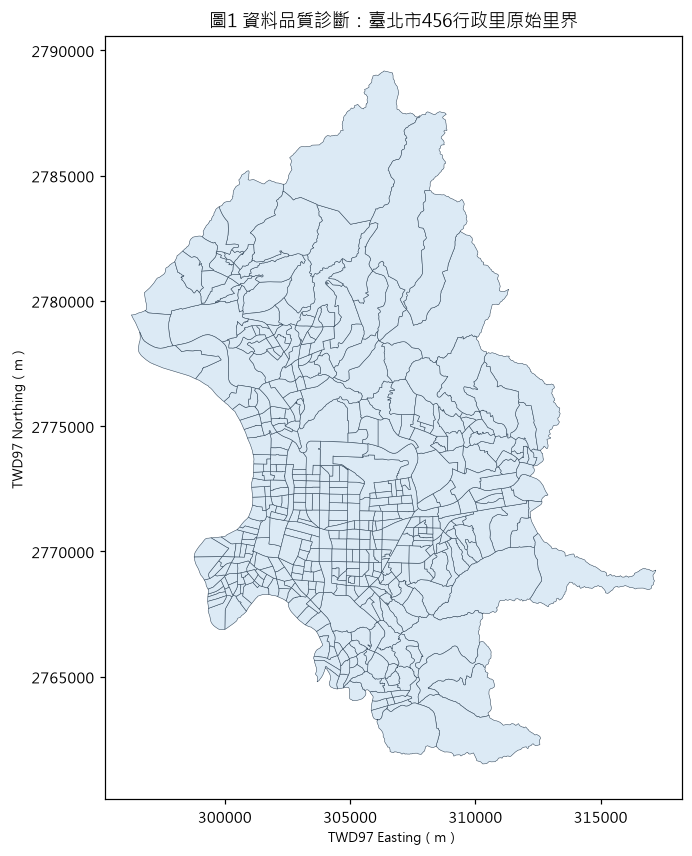

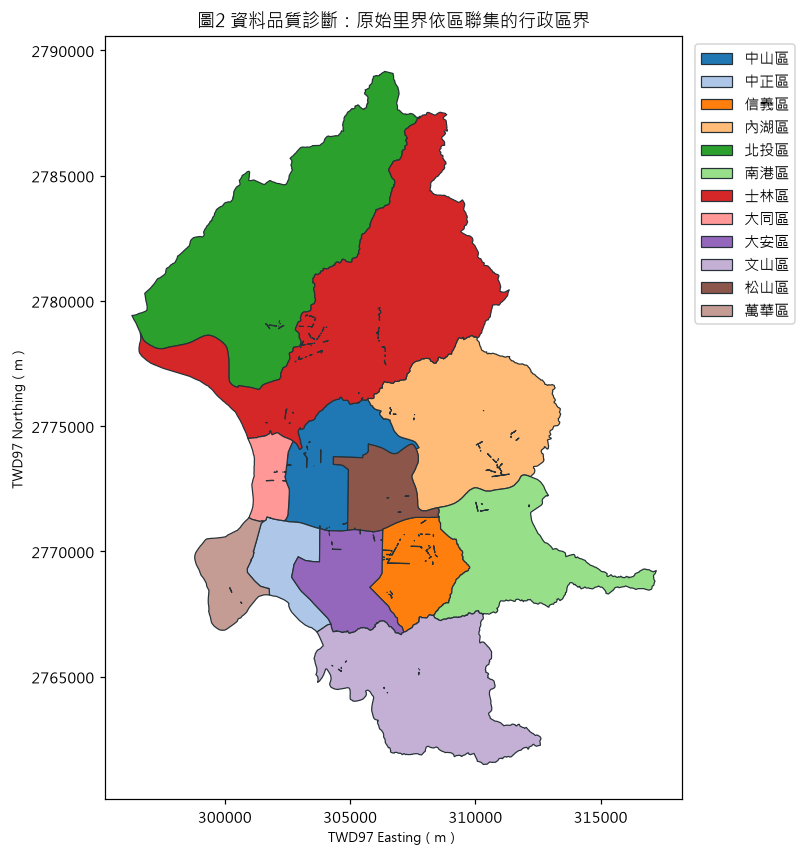

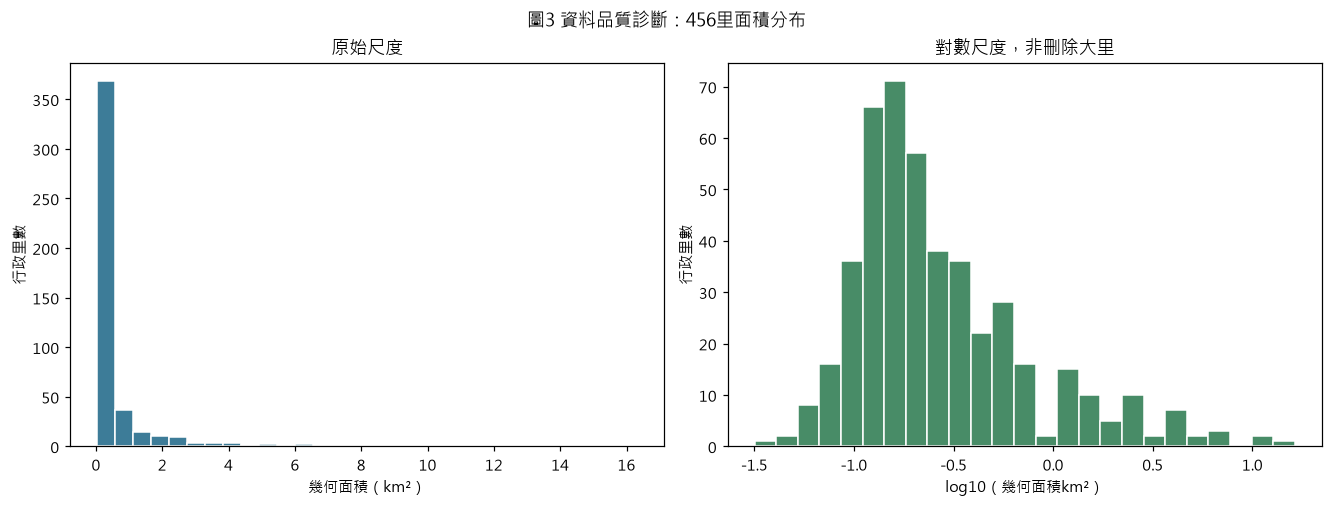

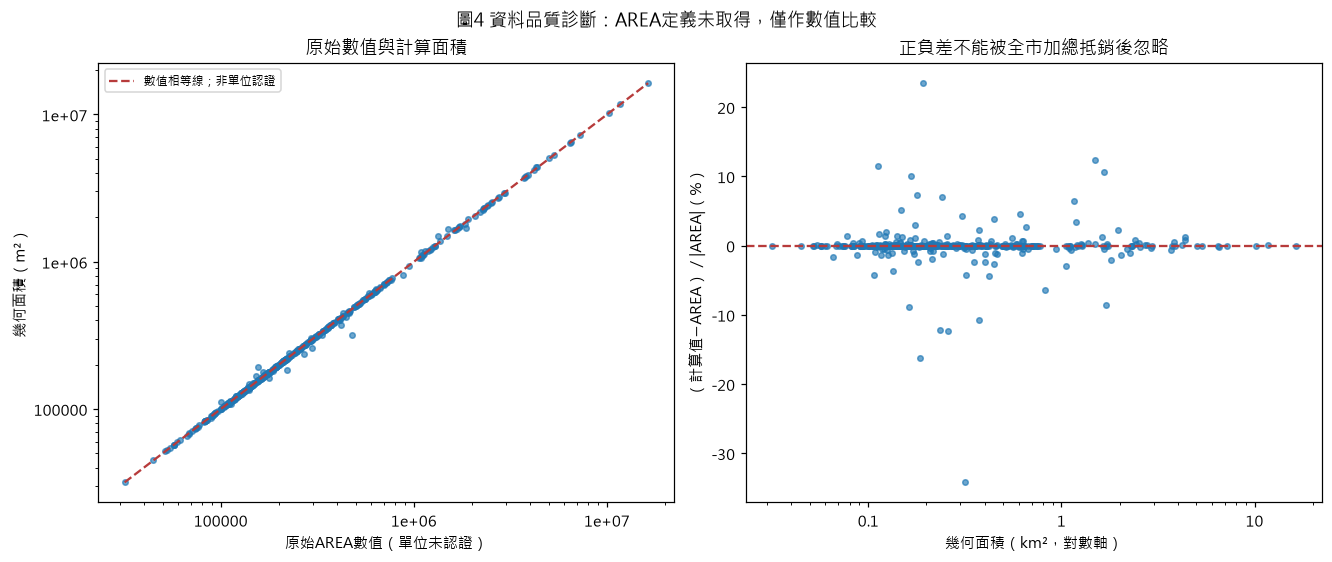

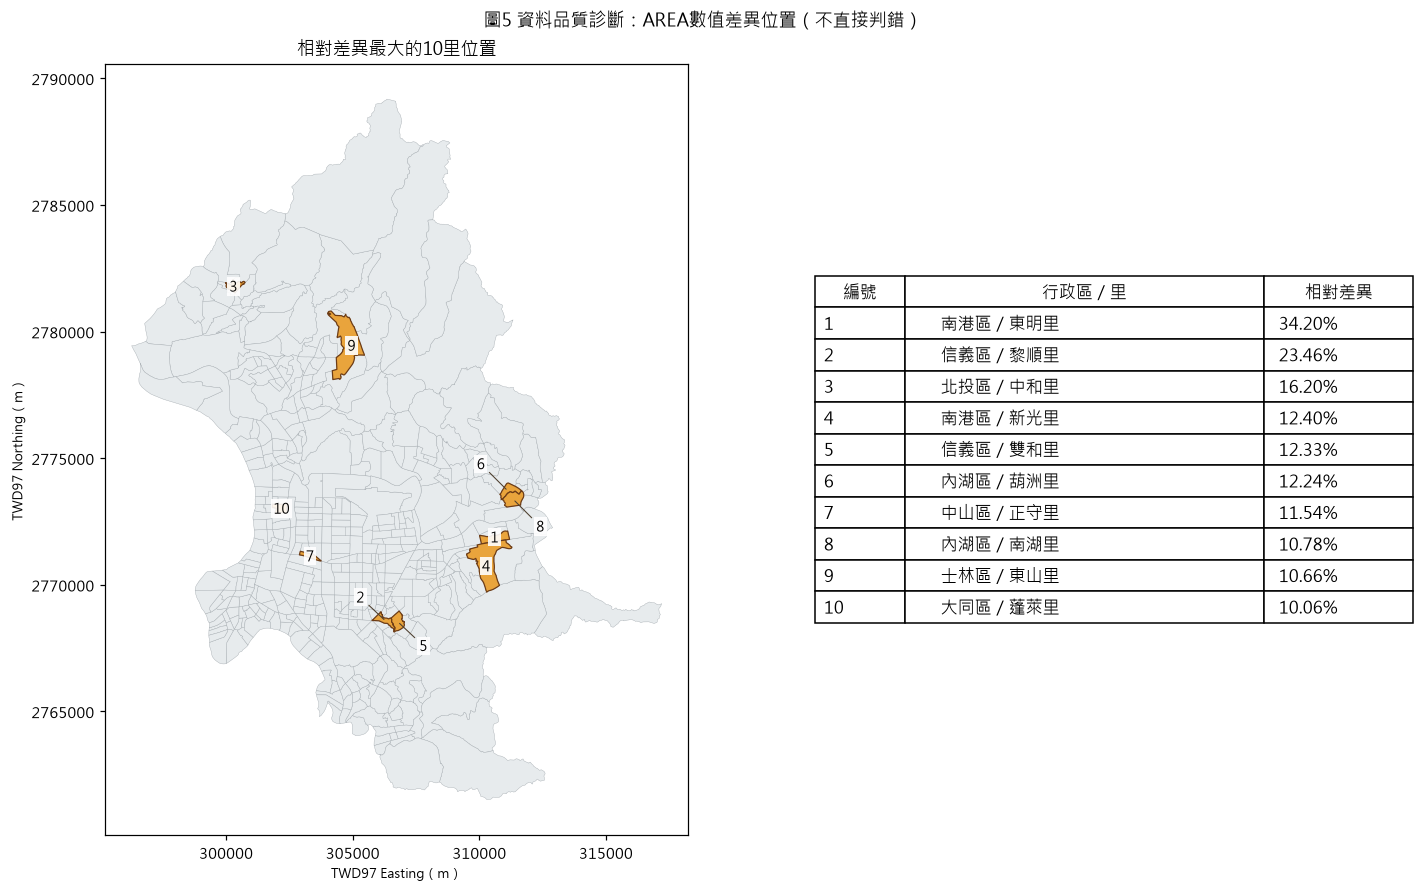

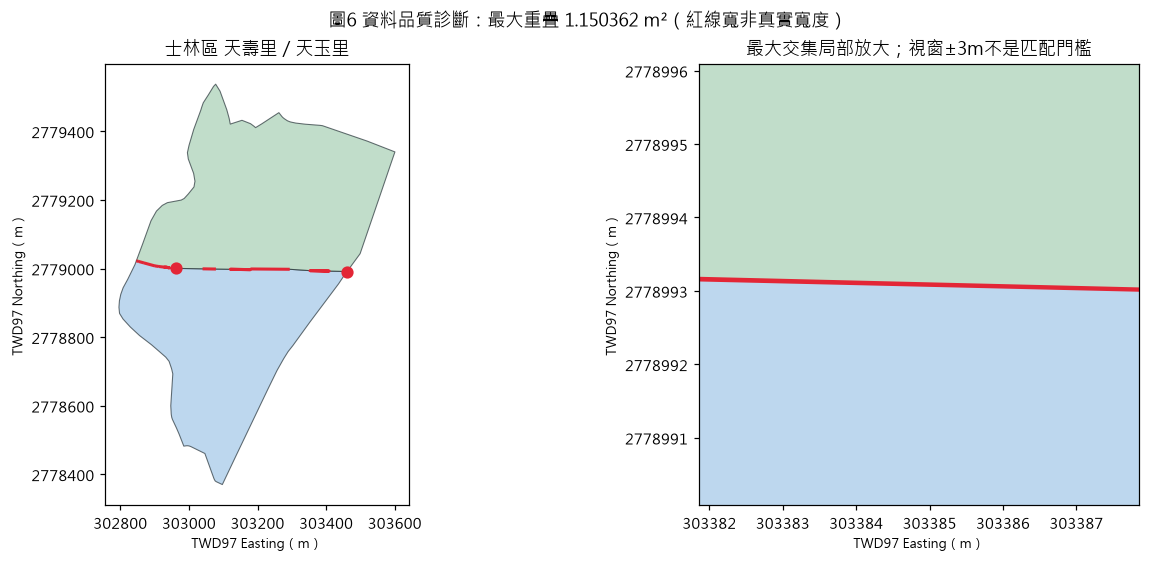

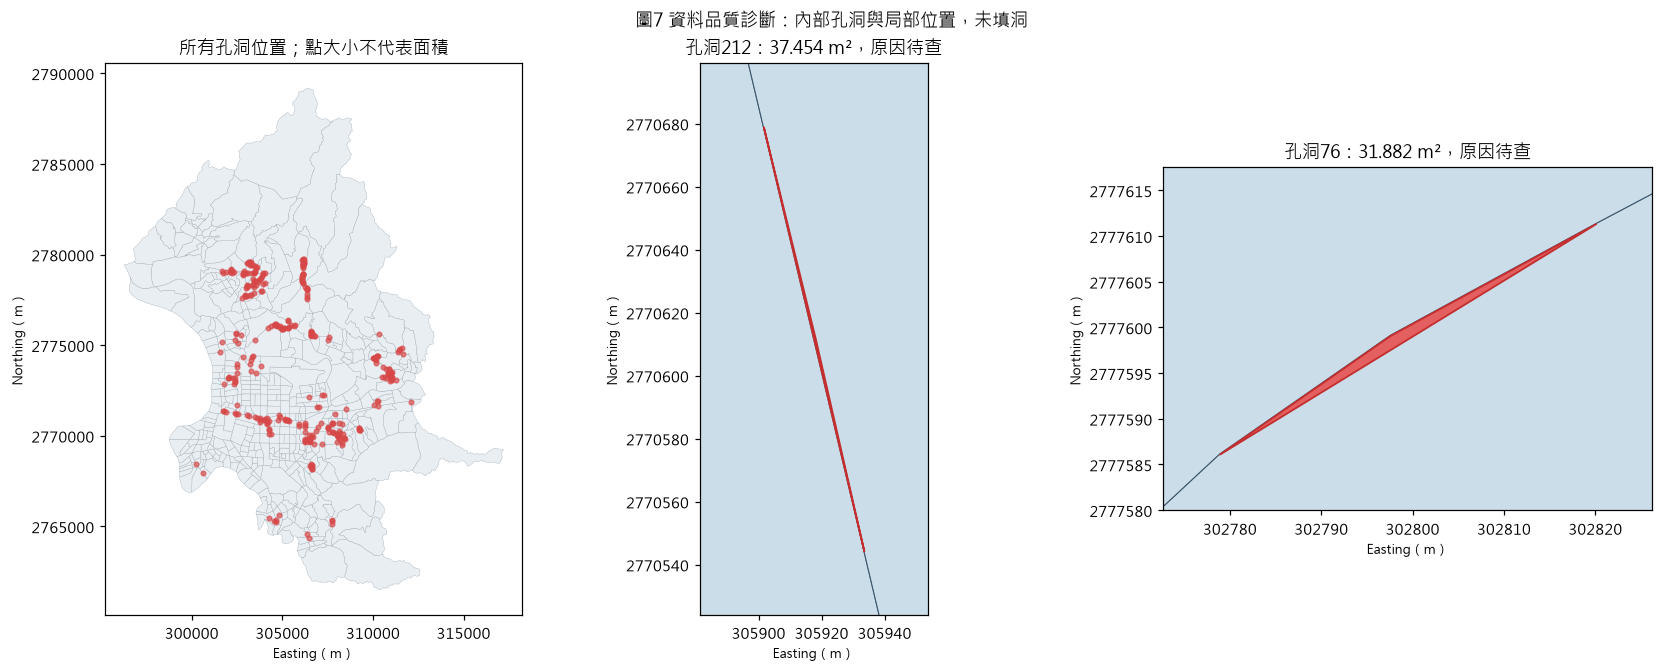

In [10]:
fig,ax=plt.subplots(figsize=(8,9))
boundary.plot(ax=ax,color='#dceaf5',edgecolor='#35495c',linewidth=.35)
ax.set(title='圖1 資料品質診斷：臺北市456行政里原始里界',xlabel='TWD97 Easting（m）',ylabel='TWD97 Northing（m）')
ax.ticklabel_format(style='plain',useOffset=False);ax.set_aspect('equal')
finish_figure(fig,'fig01_village_boundaries.png')

district_map=gpd.GeoDataFrame({'行政區':list(district_geometries)},geometry=list(district_geometries.values()),crs=boundary.crs)
fig,ax=plt.subplots(figsize=(10,9))
district_map.plot(column='行政區',categorical=True,legend=True,cmap='tab20',edgecolor='#263238',linewidth=.8,
                  legend_kwds={'loc':'upper left','bbox_to_anchor':(1.01,1)},ax=ax)
ax.set(title='圖2 資料品質診斷：原始里界依區聯集的行政區界',xlabel='TWD97 Easting（m）',ylabel='TWD97 Northing（m）')
ax.ticklabel_format(style='plain',useOffset=False);ax.set_aspect('equal')
finish_figure(fig,'fig02_district_boundaries.png')

fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
axes[0].hist(calculated/1e6,bins=30,color='#3d7c98',edgecolor='white')
axes[0].set(xlabel='幾何面積（km²）',ylabel='行政里數',title='原始尺度')
axes[1].hist(np.log10(calculated/1e6),bins=25,color='#488c67',edgecolor='white')
axes[1].set(xlabel='log10（幾何面積km²）',ylabel='行政里數',title='對數尺度，非刪除大里')
fig.suptitle('圖3 資料品質診斷：456里面積分布')
finish_figure(fig,'fig03_area_distribution.png')

fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
original=area_diagnostics.original_area
axes[0].scatter(original,calculated,s=13,alpha=.65)
low=min(original.min(),calculated.min());high=max(original.max(),calculated.max())
axes[0].plot([low,high],[low,high],color='#b73b3b',linestyle='--',label='數值相等線；非單位認證')
axes[0].set(xscale='log',yscale='log',xlabel='原始AREA數值（單位未認證）',ylabel='幾何面積（m²）',title='原始數值與計算面積')
axes[0].legend(fontsize=8)
axes[1].scatter(calculated/1e6,100*area_diagnostics.signed_relative_difference,s=13,alpha=.65)
axes[1].axhline(0,color='#b73b3b',linestyle='--')
axes[1].set(xscale='log',xlabel='幾何面積（km²，對數軸）',ylabel='（計算值−AREA）／|AREA|（%）',title='正負差不能被全市加總抵銷後忽略')
from matplotlib.ticker import FuncFormatter, NullFormatter
# Plain numeric log-axis labels avoid a missing mathtext minus glyph in the Chinese font.
for axis in (axes[0].xaxis,axes[0].yaxis,axes[1].xaxis):
    axis.set_major_formatter(FuncFormatter(lambda value,position:f'{value:g}'))
    axis.set_minor_formatter(NullFormatter())
fig.suptitle('圖4 資料品質診斷：AREA定義未取得，僅作數值比較')
finish_figure(fig,'fig04_area_comparison.png')

top=area_diagnostics.nlargest(10,'relative_area_difference')
fig,axes=plt.subplots(1,2,figsize=(13,8),gridspec_kw={'width_ratios':[1.35,1]},constrained_layout=True)
boundary.plot(ax=axes[0],color='#e7ebed',edgecolor='#a2a9ae',linewidth=.25)
boundary.loc[top.index].plot(ax=axes[0],color='#e9a43c',edgecolor='#6d3c16',linewidth=.8)
for rank,(i,row) in enumerate(top.iterrows(),1):
    p=boundary.geometry.iloc[i].representative_point()
    offset={2:(-17,16),5:(17,-16),6:(-18,18),8:(18,-18)}.get(rank,(0,0))
    axes[0].annotate(str(rank),xy=(p.x,p.y),xytext=offset,textcoords='offset points',
                     fontsize=9,ha='center',va='center',
                     bbox={'facecolor':'white','alpha':.9,'pad':1.5,'edgecolor':'none'},
                     arrowprops={'arrowstyle':'-','color':'#4e4030','lw':.7} if offset!=(0,0) else None)
axes[0].set(title='相對差異最大的10里位置',xlabel='TWD97 Easting（m）',ylabel='TWD97 Northing（m）')
axes[0].ticklabel_format(style='plain',useOffset=False);axes[0].set_aspect('equal')
axes[1].axis('off')
table_data=[[str(rank),row.TNAME+'／'+row.VNAME,f'{100*row.relative_area_difference:.2f}%'] for rank,(_,row) in enumerate(top.iterrows(),1)]
t=axes[1].table(cellText=table_data,colLabels=['編號','行政區／里','相對差異'],loc='center',cellLoc='left',colWidths=[.15,.6,.25])
t.auto_set_font_size(False);t.set_fontsize(11);t.scale(1,1.8)
fig.suptitle('圖5 資料品質診斷：AREA數值差異位置（不直接判錯）')
finish_figure(fig,'fig05_largest_area_differences.png')

def polygon_parts(g):
    if g.geom_type=='Polygon':return [g]
    if hasattr(g,'geoms'):return [p for item in g.geoms for p in polygon_parts(item)]
    return []

if len(overlaps):
    row=overlaps.iloc[0];k=int(row.pair_index);i,j=pairs[:,k]
    fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
    local=boundary.iloc[[i,j]]
    for ax in axes:
        local.plot(ax=ax,color=['#a1c7e7','#a7cfb4'],edgecolor='#263238',alpha=.7,linewidth=.7)
        gpd.GeoSeries([intersections[k]],crs=boundary.crs).plot(ax=ax,color='#e32636',edgecolor='#e32636',linewidth=2)
        ax.set(xlabel='TWD97 Easting（m）',ylabel='TWD97 Northing（m）');ax.ticklabel_format(style='plain',useOffset=False)
    axes[0].set_title(row['區1']+' '+row['里1']+'／'+row['里2'])
    largest=max(polygon_parts(intersections[k]),key=lambda p:p.area)
    center=largest.representative_point()
    axes[1].set_xlim(center.x-3,center.x+3);axes[1].set_ylim(center.y-3,center.y+3)
    axes[1].set_title('最大交集局部放大；視窗±3m不是匹配門檻')
    fig.suptitle(f'圖6 資料品質診斷：最大重疊 {row.intersection_area_m2:.6f} m²（紅線寬非真實寬度）')
    finish_figure(fig,'fig06_overlap_detail.png')

if len(holes):
    fig,axes=plt.subplots(1,3,figsize=(15,6),constrained_layout=True)
    boundary.plot(ax=axes[0],color='#e9eef2',edgecolor='#94a2ad',linewidth=.2)
    axes[0].scatter(holes.x,holes.y,s=9,color='#d74747',alpha=.65)
    axes[0].set_title('所有孔洞位置；點大小不代表面積')
    top_holes=holes.nlargest(2,'area_m2')
    for ax,(_,row) in zip(axes[1:],top_holes.iterrows()):
        h=HOLES[int(row.hole_id)-1];minx,miny,maxx,maxy=h.bounds
        ids=boundary.sindex.query(h,predicate='intersects')
        boundary.iloc[ids].plot(ax=ax,color='#cbdde9',edgecolor='#3b566b',linewidth=.7)
        gpd.GeoSeries([h],crs=boundary.crs).plot(ax=ax,color='#e45f5f',edgecolor='#c52e2e',linewidth=1.2)
        padding=max(maxx-minx,maxy-miny)*.15
        ax.set_xlim(minx-padding,maxx+padding);ax.set_ylim(miny-padding,maxy+padding)
        ax.set_title(f'孔洞{int(row.hole_id)}：{row.area_m2:.3f} m²，原因待查')
    for ax in axes:
        ax.set(xlabel='Easting（m）',ylabel='Northing（m）');ax.ticklabel_format(style='plain',useOffset=False);ax.set_aspect('equal')
    fig.suptitle('圖7 資料品質診斷：內部孔洞與局部位置，未填洞')
    finish_figure(fig,'fig07_hole_locations.png')


## 10. Quality Conclusions and Sequential Handoff
個體有效性、CRS與必要屬性通過，不等於無重疊、無孔洞、外部覆蓋完整或歷史版本已確認。
本次所有正面積對與孔洞完整保留，面積容差只作敏感度，不修復、不裁切、不填洞。
原AREA總量接近幾何總量仍可能掩蓋個別里數值差異；AREA定義與原始版本要補證。

可提出兩年共用現有hash作「固定研究地理單位」的候選方案，但須學生明確採用並記限制；
不能寫成2024–2025原生行政邊界一致，人口及環境的時間／空間對齊仍另待完成。
正式事故歸里還須事故datum、候選多重／未匹配政策及拓樸問題處理／敏感度審查。
本次只記錄Unit 1.1審查決策，不重跑其傷亡敏感度或分群規格。

從乾淨DSSI Urban Crash kernel執行全部code cells即可重現；Notebook不連網、官方來源查閱日固定2026-11-26。
若來源hash不符先停查，不更新綁定以強行通過。完成後停止，未進入Unit 1.3。


In [11]:
assert boundary.geometry.to_wkb().equals(original_wkb),'In-memory source geometry changed'
for relative,digest in EXPECTED_SHA256.items():assert sha(source_file(relative))==digest,relative
assert OUTPUTS=={}
print({'bound_inputs_unchanged':True,'in_memory_raw_geometry_unchanged':True,'input_files_checked':len(EXPECTED_SHA256),
       'processed_datasets':0,'repaired_geometry_exports':0,'real_accident_joins':0,
       'synthetic_join_tests_passed':True,'diagnostic_figures':FIGURES,
       'historical_geometry_equality':'unconfirmed','AREA_official_definition':'unconfirmed',
       'external_coverage':'not fully validated','accident_datum':'unconfirmed'})


{'bound_inputs_unchanged': True, 'in_memory_raw_geometry_unchanged': True, 'input_files_checked': 7, 'processed_datasets': 0, 'repaired_geometry_exports': 0, 'real_accident_joins': 0, 'synthetic_join_tests_passed': True, 'diagnostic_figures': ['data/temp/unit12_validation/fig01_village_boundaries.png', 'data/temp/unit12_validation/fig02_district_boundaries.png', 'data/temp/unit12_validation/fig03_area_distribution.png', 'data/temp/unit12_validation/fig04_area_comparison.png', 'data/temp/unit12_validation/fig05_largest_area_differences.png', 'data/temp/unit12_validation/fig06_overlap_detail.png', 'data/temp/unit12_validation/fig07_hole_locations.png'], 'historical_geometry_equality': 'unconfirmed', 'AREA_official_definition': 'unconfirmed', 'external_coverage': 'not fully validated', 'accident_datum': 'unconfirmed'}
